# Proyecto Final — Aplicaciones de Analítica de Datos
## Sensor Virtual para la Estimación de Emisiones de $\text{NO}_x$ en una Turbina de Gas mediante Variables Ambientales y Operativas (Evaluación Interanual 2011–2015)

**Universidad Iberoamericana** · *Aplicaciones de Analítica de Datos*  
**Integrantes:** José Adrián Bazaldua Huerta · Sebastián de Jesús Enguilo Ruiz  
**Fuente oficial de datos:** [UCI Machine Learning Repository — Gas Turbine CO and NOx Emission Data Set](https://archive.ics.uci.edu/dataset/551/gas+turbine+co+and+nox+emission+data+set) ([DOI: 10.24432/C5WC95](https://doi.org/10.24432/C5WC95)) · Artículo de referencia: Kaya, Tüfekci y Uzun (2019).

---

### 1. Problema, Objetivos y Justificación de Ingeniería

* **Problema central:** Los sistemas físicos de monitoreo continuo de emisiones (*CEMS*) para óxidos de nitrógeno ($\text{NO}_x = \text{NO} + \text{NO}_2$) requieren calibración frecuente, consumibles y mantenimiento especializado. Surge la pregunta de ingeniería:
  > **¿Cuánto mejora la estimación horaria de $\text{NO}_x$ ($\text{mg/m}^3$) al incorporar los sensores internos del ciclo termodinámico de la turbina frente a emplear únicamente variables meteorológicas ambientales (`AT`, `AP`, `AH`), y en qué medida se conserva dicho desempeño en años posteriores (2014–2015) no vistos durante el desarrollo?**
* **Objetivo general:** Diseñar, validar y evaluar rigurosamente un **sistema de sensor virtual (*soft sensor*)** para estimar la concentración contemporánea de `NOX` sin depender del analizador de `CO`, respetando el orden temporal de operación entre 2011 y 2015.
* **Objetivos específicos:**
  1. Auditar la integridad y comportamiento estadístico de las variables en el bloque de entrenamiento (`2011–2012`, $15{,}039$ registros horarios) sin fuga de información (*data leakage*).
  2. Identificar mediante técnicas no supervisadas vistas en el **Módulo 2** (`PCA`, `K-Means`) e inferencia del **Módulo 1** (`ANOVA`, `Tukey HSD`, `Kruskal-Wallis`) los regímenes físicos de carga de la turbina y su relación no lineal con `NOX`.
  3. Comparar en validación (`2013`, $7{,}152$ registros) modelos supervisados vistos en el curso (**Regresión Lineal MCO**, **Regularización Ridge/Lasso**, **Árboles de Decisión CART**, **Bosques Aleatorios / Random Forest**, **SVR con Kernel RBF** y **Ensambles por Agregación**), cuantificando la ganancia incremental de los sensores internos (**Set B** frente a **Set A**).
  4. Evaluar el desempeño fuera de muestra en los años futuros **`2014` y `2015`** ($14{,}542$ registros), diagnosticar la deriva física de operación (*concept/covariate shift*) con **`Isolation Forest`** y probar el sistema integrado ante escenarios operativos reales.

> **Nota de transparencia académica sobre técnicas empleadas:**  
> El núcleo del proyecto utiliza estrictamente los métodos vistos en clase (**Módulo 1:** Exploración, Estandarización Z-score, ANOVA + Tukey HSD + Kruskal-Wallis, Regresión Lineal MCO y Regularización L1/L2, Árboles CART, Random Forest, SVM/SVR y Ensambles; **Módulo 2:** PCA, K-Means e Isolation Forest). Cuando incorporamos una herramienta diagnóstica o extensión complementaria no cubierta directamente en diapositivas (**Factor de Inflación de la Varianza `VIF`**, **Validación Cruzada por Bloques Temporales `TimeSeriesSplit`**, **Expansión Polinomial de Grado 2** para interacciones termodinámicas, e **`HistGradientBoosting`** sólo como cota de comparación externa), se señala explícitamente con una nota `[Técnica complementaria fuera de clase]`.


---
## 2. Importación de librerías y carga reproducible (Local y Google Colab)

El siguiente bloque funciona de manera transparente tanto en el repositorio local (`data/raw/`) como si se abre directamente en **Google Colab**: si no encuentra los cinco CSV locales, descarga automáticamente el archivo oficial de UCI, comprueba su huella criptográfica **SHA-256** original y carga los cinco años (`2011` a `2015`) sin modificar valores ni unidades.

In [1]:
import hashlib
import io
import urllib.request
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import tukey_hsd

from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    VotingRegressor,
    IsolationForest,
    HistGradientBoostingRegressor,
)
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, silhouette_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep', font_scale=1.02)
plt.rcParams['figure.dpi'] = 110

SEMILLA = 42
np.random.seed(SEMILLA)

UCI_URL = 'https://archive.ics.uci.edu/static/public/551/gas+turbine+co+and+nox+emission+data+set.zip'
ZIP_SHA256 = '55fdb1acc25f05bd9c77aac285c424e9154ffb0dbf1bbadb56b69a1142231295'
ARCHIVOS_ESPERADOS = {
    'gt_2011.csv': (2011, 7411, 'd87ceef9aa59533cc7d924d10de241b1b06ecd11f9b26bab59191ea0f8a76b9a'),
    'gt_2012.csv': (2012, 7628, 'be54b9d0e1a7de40c55d32fa489e75de892b000c066b5a09f09a19124ee29100'),
    'gt_2013.csv': (2013, 7152, '13c437bb440ec2045bd12057e6654c41dd4107a661eac16ba2e878e897a08f9e'),
    'gt_2014.csv': (2014, 7158, 'c2a03c92c9c3207aad0c6be7de8d9b5b4bfa4720ad0efb2c1f21b6cec4d3f3fa'),
    'gt_2015.csv': (2015, 7384, '9b08f35fde0d4b138232a605db4093c2b8bf9d6757e6f1fbd9534ad616c13591'),
}

# Detectar carpeta local o descargar automáticamente en Google Colab
posibles_rutas = [Path('data/raw'), Path('../data/raw')]
ruta_datos = next((p for p in posibles_rutas if (p / 'gt_2011.csv').is_file()), None)

if ruta_datos is None:
    ruta_datos = Path('data/raw')
    ruta_datos.mkdir(parents=True, exist_ok=True)
    print('Modo Google Colab detectado: descargando ZIP oficial desde UCI...')
    payload = urllib.request.urlopen(UCI_URL, timeout=60).read()
    assert hashlib.sha256(payload).hexdigest() == ZIP_SHA256, 'Hash SHA-256 del ZIP inesperado'
    with zipfile.ZipFile(io.BytesIO(payload)) as zf:
        for nombre in ARCHIVOS_ESPERADOS:
            (ruta_datos / nombre).write_bytes(zf.read(nombre))
    print('Descarga e integridad verificadas correctamente.')

partes = []
for nombre, (anio, filas_esp, _) in ARCHIVOS_ESPERADOS.items():
    tabla_anual = pd.read_csv(ruta_datos / nombre)
    assert len(tabla_anual) == filas_esp, f'Conteo inesperado en {nombre}'
    tabla_anual['anio'] = anio
    partes.append(tabla_anual)

df = pd.concat(partes, ignore_index=True)
print(f'Dataset unido exitosamente: {df.shape[0]:,} registros horarios x {df.shape[1]} columnas')
df.head()

Dataset unido exitosamente: 36,733 registros horarios x 12 columnas


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,anio
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011


### Diccionario físico de variables y criterios de ingeniería

| Variable | Rol en el proyecto | Descripción física | Unidad publicada | Nota de ingeniería |
|---|---|---|---|---|
| `AT` | Entrada (**Set A** y **Set B**) | Temperatura del aire ambiente de admisión | °C | Afecta la densidad del aire que entra al compresor. |
| `AP` | Entrada (**Set A** y **Set B**) | Presión atmosférica ambiente | mbar | Condición barométrica de succión. |
| `AH` | Entrada (**Set A** y **Set B**) | Humedad relativa ambiente | % | La humedad absorbe calor en la cámara y modera picos térmicos. |
| `AFDP` | Entrada (**Set B**) | Presión diferencial en filtro de admisión | mbar | Sensible tanto al caudal másico como a limpiezas/cambios de filtro. |
| `GTEP` | Entrada (**Set B**) | Presión de escape de la turbina de gas | mbar | Asociada al flujo de gases de salida y régimen de carga. |
| `TIT` | Entrada (**Set B**) | Temperatura de entrada a la turbina | °C | Gobernada por la combustión antes de la expansión. |
| `TAT` | Entrada (**Set B**) | Temperatura de salida tras la expansión | °C | Controlada cerca de ~550 °C en cargas medias/parciales. |
| `TEY` | Entrada (**Set B**) | Producción de energía eléctrica horaria | MWh | Indicador directo del régimen operativo de carga (75–100%). |
| `CDP` | Entrada (**Set B**) | Presión de descarga del compresor | bar / mbar* | *Contradicción documental en la fuente (~9.9–15.2 equivale físicamente a bar); se conservan valores originales sin escalar artificialmente. |
| `CO` | **Excluida de `X`** | Monóxido de carbono en escape | mg/m³ | Se excluye de las entradas para no requerir otro analizador de gases; se usa sólo para diagnóstico físico del proceso. |
| `NOX` | **Respuesta objetivo `y`** | Concentración de óxidos de nitrógeno | mg/m³ | Variable continua a estimar por el sensor virtual. |
| `anio` | **Partición temporal** | Año del archivo original (2011–2015) | Año | Define entrenamiento (`2011–2012`), validación (`2013`) y prueba (`2014–2015`); **nunca entra en `X`**. |

---
## 3. Calidad de datos y análisis exploratorio sobre Entrenamiento (2011–2012)

Siguiendo la disciplina vista en clase para evitar cualquier contaminación del conjunto de prueba, **toda la exploración de distribuciones, correlaciones y agrupamientos se ejecuta exclusivamente sobre el bloque de entrenamiento (`2011–2012`, $15{,}039$ registros)**.

In [2]:
# Verificación global de tipos y ausencia de nulos
calidad = pd.DataFrame({
    'Tipo': df.dtypes,
    'Faltantes': df.isna().sum(),
    'Mínimo (global)': df.min().round(3),
    'Máximo (global)': df.max().round(3),
})
print('=== Auditoría de completitud y tipos (36,733 filas) ===')
display(calidad)

# Separación estricta por periodo anual
df_train = df[df['anio'].isin([2011, 2012])].copy()
df_val   = df[df['anio'] == 2013].copy()
df_test  = df[df['anio'].isin([2014, 2015])].copy()

print(f'Entrenamiento (2011-2012): {len(df_train):,} filas ({len(df_train)/len(df):.1%})')
print(f'Validación    (2013)     : {len(df_val):,} filas ({len(df_val)/len(df):.1%})')
print(f'Prueba final  (2014-2015): {len(df_test):,} filas ({len(df_test)/len(df):.1%})')

print('\n=== Estadísticos descriptivos en Entrenamiento (2011-2012) ===')
display(df_train.drop(columns='anio').describe().T.round(3))

=== Auditoría de completitud y tipos (36,733 filas) ===


,Tipo,Faltantes,Mínimo (global),Máximo (global)
AT,float64,0,-6.235,37.103
AP,float64,0,985.850,1036.600
AH,float64,0,24.085,100.200
AFDP,float64,0,2.087,7.611
GTEP,float64,0,17.698,40.716
TIT,float64,0,1000.800,1100.900
TAT,float64,0,511.040,550.610
TEY,float64,0,100.020,179.500
CDP,float64,0,9.852,15.159
CO,float64,0,0.000,44.103


Entrenamiento (2011-2012): 15,039 filas (40.9%)
Validación    (2013)     : 7,152 filas (19.5%)
Prueba final  (2014-2015): 14,542 filas (39.6%)

=== Estadísticos descriptivos en Entrenamiento (2011-2012) ===


,count,mean,std,min,25%,50%,75%,max
AT,15039.0,17.764,7.574,0.522,11.408,18.186,23.862,34.929
AP,15039.0,1013.199,6.411,985.850,1008.900,1012.800,1016.900,1034.200
AH,15039.0,79.124,13.793,30.344,69.750,82.266,90.044,100.200
AFDP,15039.0,4.200,0.760,2.087,3.724,4.186,4.551,7.611
GTEP,15039.0,25.419,4.174,17.878,23.294,25.082,27.184,37.402
TIT,15039.0,1083.799,16.528,1000.800,1079.600,1088.700,1096.000,1100.800
TAT,15039.0,545.396,7.867,512.450,542.170,549.890,550.060,550.610
TEY,15039.0,134.188,15.830,100.170,127.985,133.780,140.895,174.610
CDP,15039.0,12.102,1.103,9.904,11.622,12.025,12.578,15.081
CO,15039.0,1.972,2.222,0.000,0.858,1.390,2.160,44.103


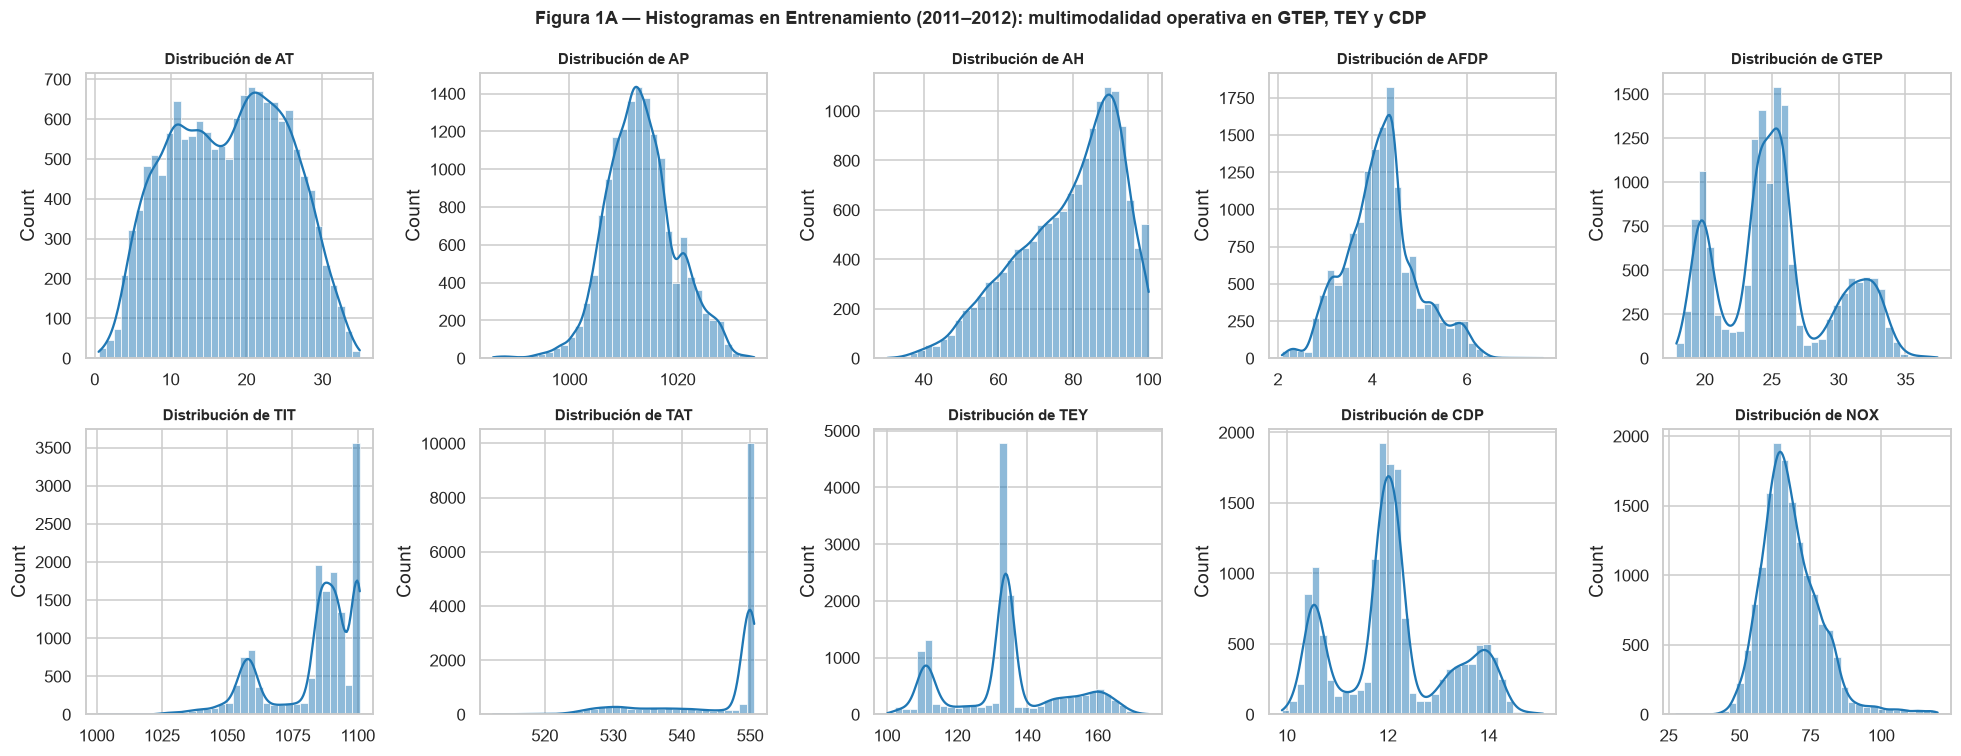

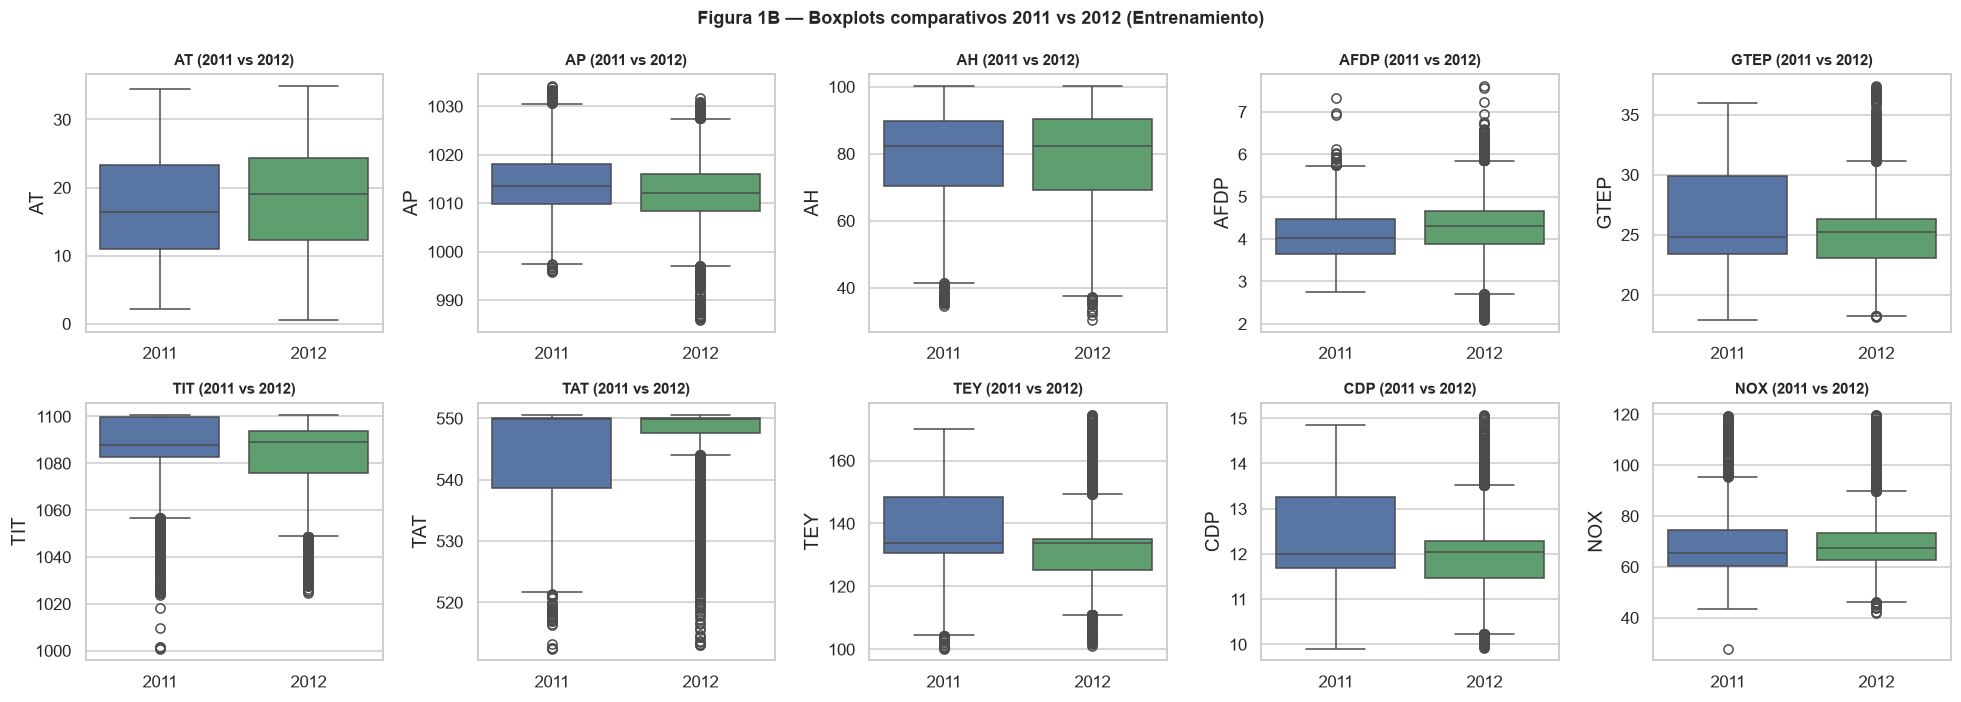

In [3]:
# Figura 1: Histogramas y Boxplots en Entrenamiento (2011-2012)
vars_fisicas = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP', 'NOX']

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for col, ax in zip(vars_fisicas, axes.flat):
    sns.histplot(df_train[col], bins=35, kde=True, ax=ax, color='#1f77b4', edgecolor='white')
    ax.set_title(f'Distribución de {col}', fontweight='bold', fontsize=10)
    ax.set_xlabel('')
fig.suptitle('Figura 1A — Histogramas en Entrenamiento (2011–2012): multimodalidad operativa en GTEP, TEY y CDP', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
for col, ax in zip(vars_fisicas, axes.flat):
    sns.boxplot(data=df_train, x='anio', y=col, ax=ax, palette=['#4c72b0', '#55a868'])
    ax.set_title(f'{col} (2011 vs 2012)', fontweight='bold', fontsize=10)
    ax.set_xlabel('')
fig.suptitle('Figura 1B — Boxplots comparativos 2011 vs 2012 (Entrenamiento)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

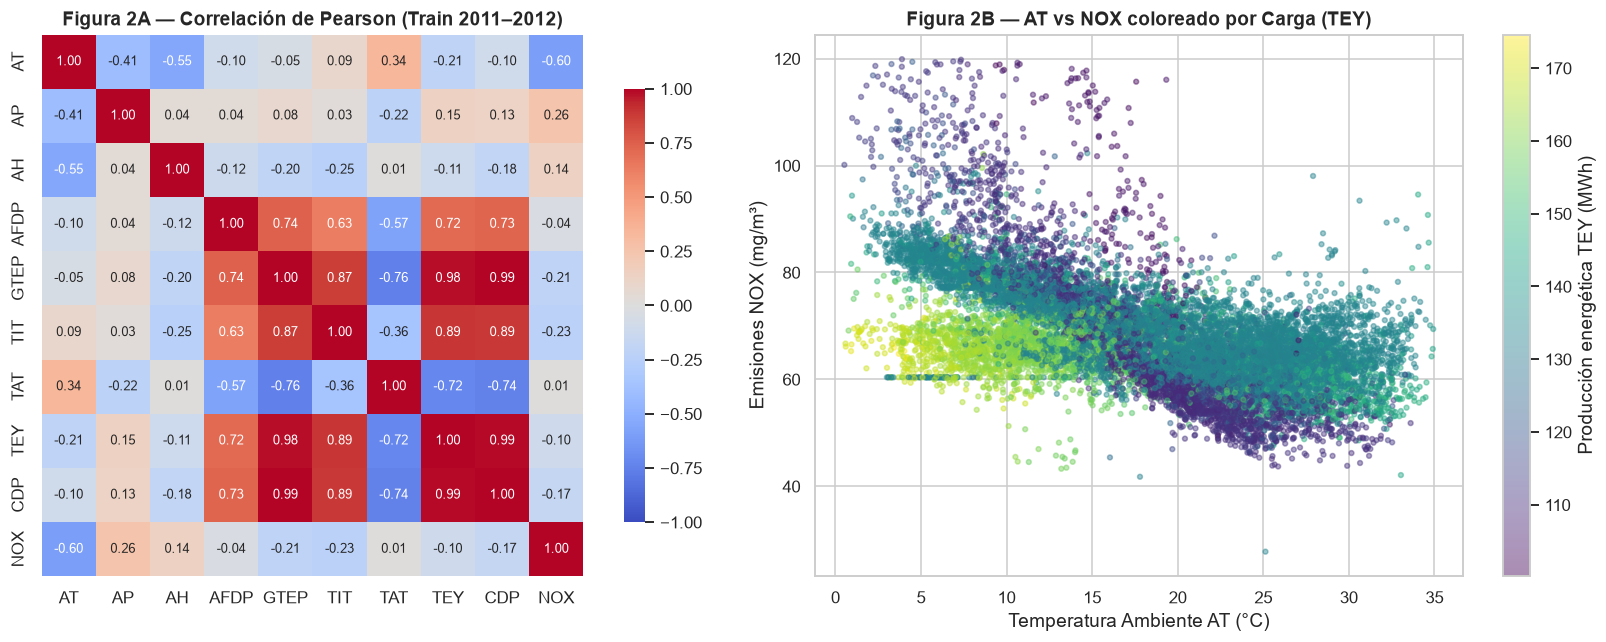

In [4]:
# Figura 2: Matriz de correlación de Pearson y relación física AT vs NOX coloreada por carga (TEY)
corr_train = df_train[vars_fisicas].corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    corr_train, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
    square=True, cbar_kws={'shrink': 0.8}, ax=axes[0], annot_kws={'size': 8.5}
)
axes[0].set_title('Figura 2A — Correlación de Pearson (Train 2011–2012)', fontweight='bold')

pts = axes[1].scatter(
    df_train['AT'], df_train['NOX'],
    c=df_train['TEY'], cmap='viridis', s=10, alpha=0.45
)
cbar = plt.colorbar(pts, ax=axes[1])
cbar.set_label('Producción energética TEY (MWh)')
axes[1].set_xlabel('Temperatura Ambiente AT (°C)')
axes[1].set_ylabel('Emisiones NOX (mg/m³)')
axes[1].set_title('Figura 2B — AT vs NOX coloreado por Carga (TEY)', fontweight='bold')

plt.tight_layout()
plt.show()

### Interpretación de la exploración inicial
1. **Completitud y rangos físicos:** Las $36{,}733$ observaciones son numéricas finitas con **cero valores faltantes**. No eliminamos los puntos fuera de los bigotes de `NOX` o `AP` porque corresponden a episodios reales de operación invernal y picos de emisión que el sensor virtual precisamente debe estimar.
2. **Redundancia severa entre variables internas:** La matriz de correlación revela correlaciones casi unitarias entre `GTEP`, `TEY` y `CDP` ($r = 0.98\text{ a }0.99$), así como fuerte acoplamiento con `TIT` ($r = 0.89\text{ a }0.91$). En una regresión lineal ordinaria sin regularización, esta colinealidad inflará la varianza de los coeficientes $\hat{\beta}$.
3. **Evidencia visual de no linealidad y múltiples modos de operación:** En la **Figura 2B**, para una misma temperatura ambiente (`AT ≈ 10 °C`), coexisten distintas bandas de `NOX` según el nivel de carga `TEY`, y curiosamente la carga más alta (puntos amarillos, `TEY > 155 MWh`) presenta **menor `NOX`** que cargas intermedias a baja temperatura. Exploremos este fenómeno con las herramientas del **Módulo 2 (`PCA` y `K-Means`)** y **Módulo 1 (`ANOVA`)**.

---
## 4. Descubrimiento de regímenes operativos (`PCA` + `K-Means`) y contraste estadístico (`ANOVA` + `Tukey HSD`)

Aplicamos tres herramientas centrales del curso sobre las **9 variables de entrada (`Set B`) estandarizadas con Z-Score (`StandardScaler`)** exclusivamente en `2011–2012`:
* **¿Por qué Estandarización Z-Score y no Min-Max?** Porque variables como `TIT` ($\sim 1085\text{ °C}$) y `CDP` ($\sim 12\text{ bar}$) difieren en dos órdenes de magnitud y contienen colas operativas; `StandardScaler` centra cada variable en $\mu=0, \sigma=1$ sin comprimir el cuerpo central de datos por valores extremos.
* **`PCA` (Módulo 2):** Cuantifica cuántas dimensiones independientes reales existen detrás de los 9 sensores.
* **`K-Means` (Módulo 2) + `ANOVA / Tukey HSD / Kruskal-Wallis` (Módulo 1):** Descubre sin usar `NOX` los modos de operación de la turbina que originaban los picos de los histogramas, y verifica estadísticamente si `NOX` cambia entre regímenes.

In [5]:
SET_A = ['AT', 'AP', 'AH']
SET_B = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']

scaler_unsup = StandardScaler().fit(df_train[SET_B])
X_train_scaled = scaler_unsup.transform(df_train[SET_B])

# 1. Análisis de Componentes Principales (PCA)
pca = PCA().fit(X_train_scaled)
var_ind = pca.explained_variance_ratio_ * 100
var_acum = np.cumsum(var_ind)

tabla_pca = pd.DataFrame({
    'Componente': [f'PC{i}' for i in range(1, len(SET_B) + 1)],
    'Varianza Individual (%)': var_ind.round(2),
    'Varianza Acumulada (%)': var_acum.round(2),
})
display(tabla_pca)

# 2. Evaluación de K en K-Means (Método del Codo + Coeficiente de Silueta)
ks = list(range(2, 7))
inercias, siluetas = [], []
idx_muestra = np.random.choice(len(X_train_scaled), size=4000, replace=False)

for k in ks:
    km_temp = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(X_train_scaled)
    inercias.append(km_temp.inertia_)
    siluetas.append(silhouette_score(X_train_scaled[idx_muestra], km_temp.labels_[idx_muestra]))

# Ajustamos K=3 regímenes operativos físicos (Carga Parcial, Carga Nominal y Carga Plena)
kmeans_op = KMeans(n_clusters=3, random_state=SEMILLA, n_init=10).fit(X_train_scaled)

# Ordenamos las etiquetas de clúster de menor a mayor producción energética media (TEY) para lectura ingenieril clara
orden_carga = (
    pd.Series(df_train['TEY'].values)
    .groupby(kmeans_op.labels_)
    .mean()
    .sort_values()
    .index.tolist()
)
mapa_regimen = {viejo: nuevo for nuevo, viejo in enumerate(orden_carga)}
nombres_regimen = {
    0: 'R0: Carga Parcial (~112 MWh)',
    1: 'R1: Carga Nominal (~134 MWh)',
    2: 'R2: Carga Plena / Frío (~158 MWh)',
}

df_train['regimen_id'] = pd.Series(kmeans_op.labels_, index=df_train.index).map(mapa_regimen)
df_train['regimen'] = df_train['regimen_id'].map(nombres_regimen)

# Proyectar también validación y prueba en los regímenes aprendidos en entrenamiento
for sub_df in [df_val, df_test]:
    etiquetas_raw = kmeans_op.predict(scaler_unsup.transform(sub_df[SET_B]))
    sub_df['regimen_id'] = pd.Series(etiquetas_raw, index=sub_df.index).map(mapa_regimen)
    sub_df['regimen'] = sub_df['regimen_id'].map(nombres_regimen)

resumen_regimenes = df_train.groupby('regimen')[['TEY', 'TIT', 'TAT', 'CDP', 'AT', 'NOX']].agg(['count', 'mean', 'std'])
print('\n=== Perfil físico de los 3 regímenes descubiertos por K-Means en Entrenamiento ===')
display(resumen_regimenes.round(2))

,Componente,Varianza Individual (%),Varianza Acumulada (%)
0,PC1,55.31,55.31
1,PC2,20.37,75.68
2,PC3,10.26,85.94
3,PC4,6.31,92.26
4,PC5,4.41,96.66
5,PC6,3.27,99.94
6,PC7,0.03,99.97
7,PC8,0.02,99.99
8,PC9,0.01,100.00



=== Perfil físico de los 3 regímenes descubiertos por K-Means en Entrenamiento ===


TEY                 TIT                 \
                                  count    mean   std count     mean   std   
regimen                                                                      
R0: Carga Parcial (~112 MWh)       3428  111.90  4.06  3428  1056.31  8.54   
R1: Carga Nominal (~134 MWh)       8354  134.21  3.64  8354  1088.89  5.13   
R2: Carga Plena / Frío (~158 MWh)  3257  157.58  5.98  3257  1099.66  1.94   

                                    TAT                 CDP               \
                                  count    mean   std count   mean   std   
regimen                                                                    
R0: Carga Parcial (~112 MWh)       3428  548.13  4.53  3428  10.61  0.26   
R1: Carga Nominal (~134 MWh)       8354  549.48  1.88  8354  12.06  0.32   
R2: Carga Plena / Frío (~158 MWh)  3257  532.05  5.14  3257  13.77  0.38   

                                     AT                NOX                
                                  count   mean   std count   mean    std  
regimen                                                                   
R0: Carga Parcial (~112 MWh)       3428  17.94  6.05  3428  68.53  16.41  
R1: Carga Nominal (~134 MWh)       8354  18.98  7.95  8354  69.28   8.30  
R2: Carga Plena / Frío (~158 MWh)  3257  14.47  7.03  3257  65.05   5.74

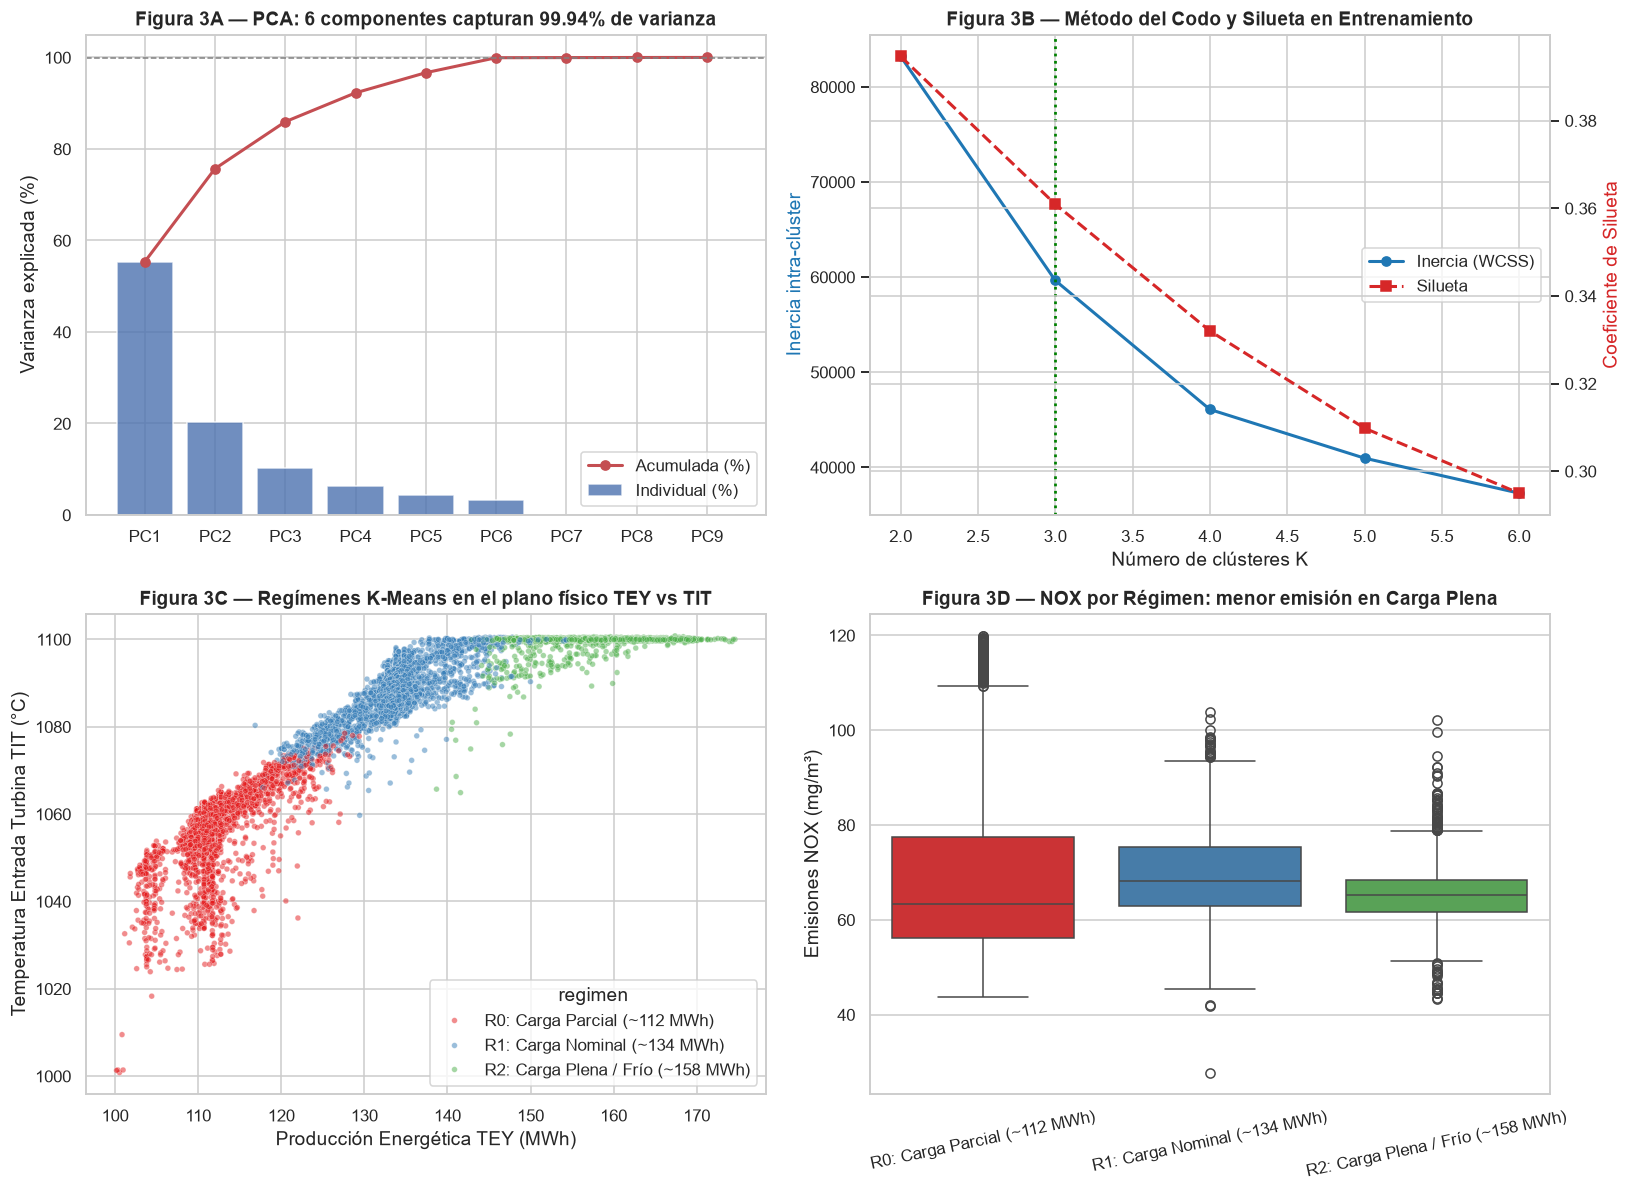

ANOVA de 1 factor (NOX ~ Régimen K-Means): F = 198.48, p-valor = 8.3333e-86
Kruskal-Wallis (respaldo no paramétrico) : H = 593.29, p-valor = 1.4779e-129

Comparaciones múltiples post-hoc de Tukey HSD (0=Parcial, 1=Nominal, 2=Plena):
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -0.746     0.001    -1.238    -0.255
 (0 - 2)      3.482     0.000     2.889     4.075
 (1 - 0)      0.746     0.001     0.255     1.238
 (1 - 2)      4.228     0.000     3.728     4.729
 (2 - 0)     -3.482     0.000    -4.075    -2.889
 (2 - 1)     -4.228     0.000    -4.729    -3.728



In [6]:
# Figura 3: PCA + Selección K-Means + Regímenes Operativos y su efecto no lineal en NOX
X_pca_2d = pca.transform(X_train_scaled)[:, :2]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 3A: Varianza explicada PCA
axes[0, 0].bar(range(1, 10), var_ind, color='#4c72b0', alpha=0.8, label='Individual (%)')
axes[0, 0].plot(range(1, 10), var_acum, marker='o', color='#c44e52', linewidth=2, label='Acumulada (%)')
axes[0, 0].axhline(99.9, ls='--', color='gray', lw=1)
axes[0, 0].set_xticks(range(1, 10))
axes[0, 0].set_xticklabels([f'PC{i}' for i in range(1, 10)])
axes[0, 0].set_ylabel('Varianza explicada (%)')
axes[0, 0].set_title('Figura 3A — PCA: 6 componentes capturan 99.94% de varianza', fontweight='bold')
axes[0, 0].legend()

# 3B: Codo y Silueta K-Means
ax_codo = axes[0, 1]
ax_sil = ax_codo.twinx()
l1 = ax_codo.plot(ks, inercias, marker='o', color='#1f77b4', lw=2, label='Inercia (WCSS)')
l2 = ax_sil.plot(ks, siluetas, marker='s', color='#d62728', lw=2, ls='--', label='Silueta')
ax_codo.axvline(3, color='green', ls=':', lw=1.8, label='Selección física K=3')
ax_codo.set_xlabel('Número de clústeres K')
ax_codo.set_ylabel('Inercia intra-clúster', color='#1f77b4')
ax_sil.set_ylabel('Coeficiente de Silueta', color='#d62728')
ax_codo.set_title('Figura 3B — Método del Codo y Silueta en Entrenamiento', fontweight='bold')
lineas = l1 + l2
ax_codo.legend(lineas, [l.get_label() for l in lineas], loc='center right')

# 3C: Regímenes en el espacio físico TEY vs TIT
sns.scatterplot(
    data=df_train, x='TEY', y='TIT', hue='regimen',
    hue_order=list(nombres_regimen.values()), palette='Set1', s=14, alpha=0.5, ax=axes[1, 0]
)
axes[1, 0].set_xlabel('Producción Energética TEY (MWh)')
axes[1, 0].set_ylabel('Temperatura Entrada Turbina TIT (°C)')
axes[1, 0].set_title('Figura 3C — Regímenes K-Means en el plano físico TEY vs TIT', fontweight='bold')

# 3D: Boxplot de NOX por régimen operativo (demostración visual del ANOVA)
sns.boxplot(
    data=df_train, x='regimen', y='NOX',
    order=list(nombres_regimen.values()), palette='Set1', ax=axes[1, 1]
)
axes[1, 1].set_xlabel('')
axes[1, 1].tick_params(axis='x', rotation=12)
axes[1, 1].set_ylabel('Emisiones NOX (mg/m³)')
axes[1, 1].set_title('Figura 3D — NOX por Régimen: menor emisión en Carga Plena', fontweight='bold')

plt.tight_layout()
plt.show()

# Contraste formal ANOVA de 1 factor + Tukey HSD + Respaldo no paramétrico Kruskal-Wallis (Módulo 1)
grupos_nox = [df_train.loc[df_train['regimen_id'] == k, 'NOX'].values for k in [0, 1, 2]]
f_anova, p_anova = stats.f_oneway(*grupos_nox)
h_kruskal, p_kruskal = stats.kruskal(*grupos_nox)
res_tukey = tukey_hsd(*grupos_nox)

print(f'ANOVA de 1 factor (NOX ~ Régimen K-Means): F = {f_anova:.2f}, p-valor = {p_anova:.4e}')
print(f'Kruskal-Wallis (respaldo no paramétrico) : H = {h_kruskal:.2f}, p-valor = {p_kruskal:.4e}')
print('\nComparaciones múltiples post-hoc de Tukey HSD (0=Parcial, 1=Nominal, 2=Plena):')
print(res_tukey)

### Hallazgo clave de ingeniería a partir de `PCA`, `K-Means` y `ANOVA`
1. **Dimensionalidad efectiva (`PCA`):** Las últimas tres componentes (`PC7`, `PC8`, `PC9`) aportan en conjunto apenas **0.06% de la varianza**, confirmando matemáticamente que `GTEP`, `TEY` y `CDP` miden el mismo grado de libertad mecánico del eje compresor-turbina.
2. **Explicación de los picos de los histogramas (`K-Means`):** Sin haber visto `NOX`, `K-Means` separa limpiamente la operación de la planta en **Carga Parcial (`~111.9 MWh`)**, **Carga Nominal (`~134.2 MWh`)** y **Carga Plena en clima fresco (`~157.6 MWh`)**.
3. **Demostración estadística de no linealidad (`ANOVA` + `Tukey HSD` + `Kruskal-Wallis`):** Tanto ANOVA ($F = 198.48, p < 10^{-85}$) como Kruskal-Wallis ($H = 593.29, p < 10^{-128}$) y todos los pares de Tukey HSD ($p \le 0.001$) confirman que la media de `NOX` **sube** de Carga Parcial (`68.53 mg/m³`) a Carga Nominal (`69.28 mg/m³`), pero **baja drásticamente en Carga Plena (`65.05 mg/m³`)**. En turbinas de gas industriales equipadas con quemadores de premezcla pobre (*Dry Low NOx*), al acercarse al 100% de carga la relación aire-combustible opera en su punto óptimo de premezcla reduciendo los puntos calientes de llama. **Por eso una recta lineal simple sobre la carga nunca podrá capturar adecuadamente el fenómeno.**

---
## 5. Conjuntos de sensores a comparar y diagnóstico de multicolinealidad

Definimos formalmente la variable de respuesta `y = NOX` y comparamos dos configuraciones reales de instrumentación:
* **Set A — Sólo sensores ambientales (3 variables):** `['AT', 'AP', 'AH']` (equivale a estimar emisiones únicamente con una estación meteorológica externa).
* **Set B — Sensores ambientales + operativos de turbina (9 variables):** `['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']` (integra la instrumentación estándar del control de la turbina, sin usar el analizador de `CO`).

> **`[Técnica complementaria fuera de clase — VIF]`:** Calculamos el **Factor de Inflación de la Varianza ($	ext{VIF}_j = 1 / (1 - R_j^2)$)** únicamente sobre entrenamiento para cuantificar cuánto se infla la varianza de los estimadores de Mínimos Cuadrados Ordinarios debido a la colinealidad.

In [7]:
X_tr_std_df = (df_train[SET_B] - df_train[SET_B].mean()) / df_train[SET_B].std()
vifs = pd.Series(
    np.diag(np.linalg.inv(X_tr_std_df.corr().values)),
    index=SET_B,
    name='VIF (Entrenamiento 2011-2012)'
).sort_values(ascending=False)

display(vifs.to_frame().round(2))

,VIF (Entrenamiento 2011-2012)
TIT,507.44
TEY,465.54
GTEP,374.95
CDP,327.48
TAT,223.03
AT,15.67
AFDP,2.74
AP,2.11
AH,1.66


---
## 6. Modelado supervisado, diagnóstico de supuestos e iteración en Validación (2013)

Entrenamos únicamente con **`2011–2012`** y evaluamos sobre **`2013`** (manteniendo `2014–2015` completamente aislado). Además calculamos la validación cruzada temporal dentro de `2011–2012` para medir estabilidad estacional:

> **`[Técnicas complementarias fuera de clase incluidas en la iteración]`:**
> 1. **`TimeSeriesSplit (5 bloques)`:** A diferencia de una partición aleatoria, respeta el orden cronológico dentro de `2011–2012` para evaluar cómo responde cada modelo cuando cambian las estaciones del año.
> 2. **`PolynomialFeatures(grado=2) + Ridge`:** Extiende la regresión lineal con regularización $L_2$ vista en clase añadiendo productos cruzados físicos (ej. `TIT × AT`, `CDP × TAT`), indispensables para aproximar la cinética térmica no lineal de Zeldovich sin perder capacidad de extrapolación paramétrica.
> 3. **`HistGradientBoostingRegressor`:** Se incluye exclusivamente como **referencia externa** para comprobar si los algoritmos vistos en clase (`Random Forest`, `SVR RBF` y su `Ensamble`) alcanzan un nivel competitivo frente a métodos de *boosting* modernos.

=== Inferencia de Coeficientes MCO en Entrenamiento 2011–2012 ===


,Variable,Beta_Estandarizado,Error_Estandar,Estadistico_t,p_valor
0,Intercepto,68.1909,0.0573,1189.80,0.0000e+00
1,AT,-13.1261,0.2269,-57.85,0.0000e+00
2,AP,-1.6718,0.0832,-20.10,0.0000e+00
3,AH,-4.0269,0.0738,-54.55,0.0000e+00
4,AFDP,1.8032,0.0949,19.01,0.0000e+00
5,GTEP,-14.2230,1.1098,-12.82,0.0000e+00
6,TIT,28.3616,1.2911,21.97,0.0000e+00
7,TAT,-15.2476,0.8559,-17.81,0.0000e+00
8,TEY,-29.5985,1.2366,-23.94,0.0000e+00
9,CDP,1.9557,1.0372,1.89,5.9372e-02


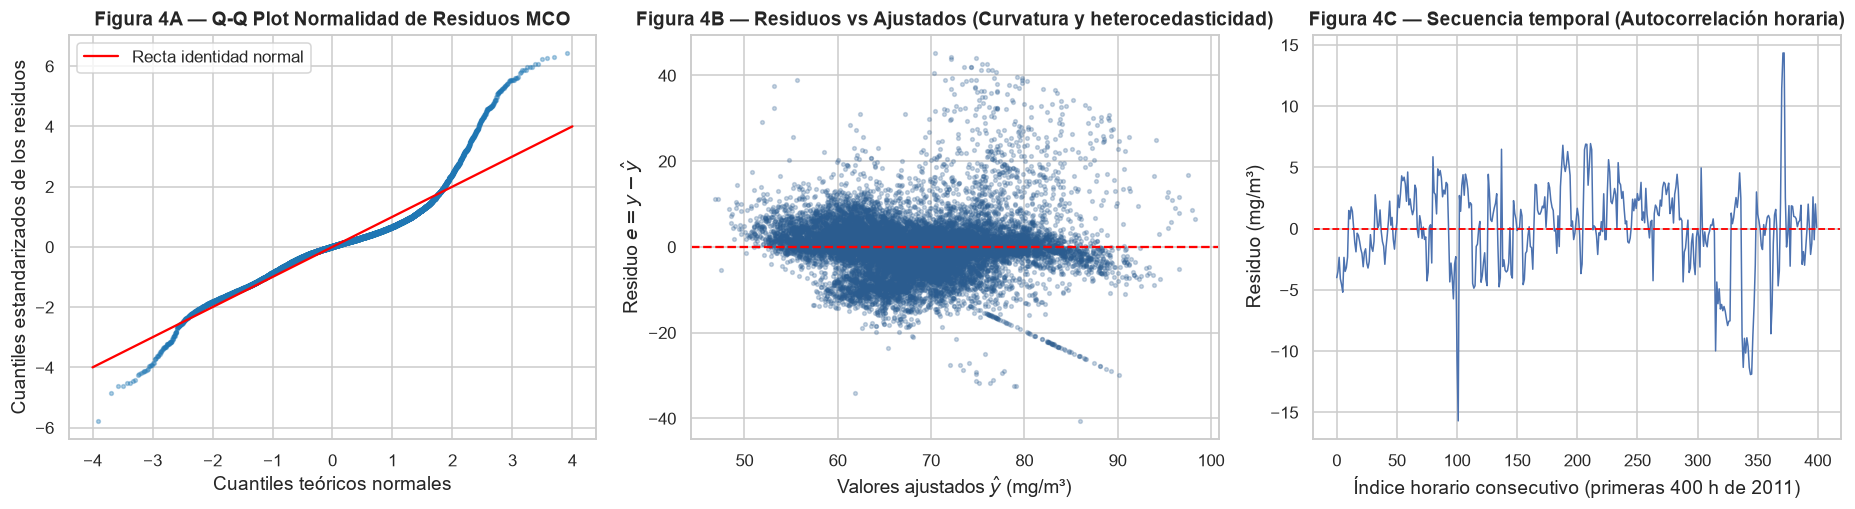

In [8]:
y_train = df_train['NOX'].values
y_val   = df_val['NOX'].values
y_test  = df_test['NOX'].values

# Primero ajustamos MCO analítico en Entrenamiento para auditar significancia (estadístico t, p-valor) y supuestos de residuos (Módulo 1)
X_ols_esc = StandardScaler().fit_transform(df_train[SET_B])
X_ols_dis = np.column_stack([np.ones(len(X_ols_esc)), X_ols_esc])
beta_ols, _, _, _ = np.linalg.lstsq(X_ols_dis, y_train, rcond=None)
pred_ols_tr = X_ols_dis @ beta_ols
residuos_ols = y_train - pred_ols_tr

n_obs, p_param = X_ols_dis.shape
s2_res = float((residuos_ols @ residuos_ols) / (n_obs - p_param))
se_beta = np.sqrt(np.diag(s2_res * np.linalg.inv(X_ols_dis.T @ X_ols_dis)))
t_stats = beta_ols / se_beta
p_vals  = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=n_obs - p_param))

tabla_ols = pd.DataFrame({
    'Variable': ['Intercepto'] + SET_B,
    'Beta_Estandarizado': beta_ols.round(4),
    'Error_Estandar': se_beta.round(4),
    'Estadistico_t': t_stats.round(2),
    'p_valor': [f'{pv:.4e}' for pv in p_vals],
})
print('=== Inferencia de Coeficientes MCO en Entrenamiento 2011–2012 ===')
display(tabla_ols)

# Figura 4: Diagnóstico de los 3 supuestos clásicos de los residuos en Regresión Lineal MCO (vistos en clase)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

res_z = (residuos_ols - residuos_ols.mean()) / residuos_ols.std()
(osm, osr), _ = stats.probplot(res_z, dist='norm')
axes[0].scatter(osm, osr, s=6, alpha=0.35, color='#1f77b4')
axes[0].plot([-4, 4], [-4, 4], color='red', lw=1.5, label='Recta identidad normal')
axes[0].set_xlabel('Cuantiles teóricos normales')
axes[0].set_ylabel('Cuantiles estandarizados de los residuos')
axes[0].set_title('Figura 4A — Q-Q Plot Normalidad de Residuos MCO', fontweight='bold')
axes[0].legend()

axes[1].scatter(pred_ols_tr, residuos_ols, s=6, alpha=0.25, color='#2b5c8f')
axes[1].axhline(0, color='red', ls='--', lw=1.5)
axes[1].set_xlabel('Valores ajustados $\hat{y}$ (mg/m³)')
axes[1].set_ylabel('Residuo $e = y - \hat{y}$')
axes[1].set_title('Figura 4B — Residuos vs Ajustados (Curvatura y heterocedasticidad)', fontweight='bold')

axes[2].plot(residuos_ols[:400], lw=1, color='#4c72b0')
axes[2].axhline(0, color='red', ls='--', lw=1.2)
axes[2].set_xlabel('Índice horario consecutivo (primeras 400 h de 2011)')
axes[2].set_ylabel('Residuo (mg/m³)')
axes[2].set_title('Figura 4C — Secuencia temporal (Autocorrelación horaria)', fontweight='bold')

plt.tight_layout()
plt.show()

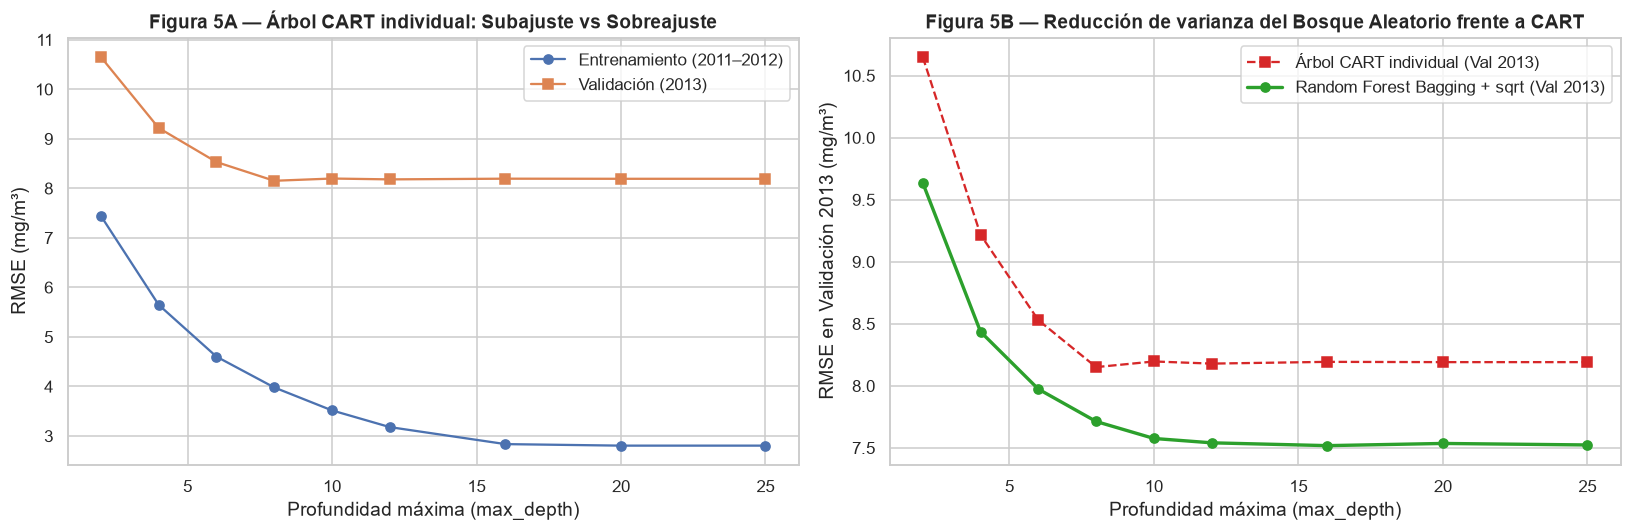

In [9]:
# Figura 5: Curva de Complejidad (Subajuste vs Sobreajuste) en Árboles CART y descorrelación en Random Forest
profundidades = [2, 4, 6, 8, 10, 12, 16, 20, 25]
rmse_tr_cart, rmse_va_cart = [], []
rmse_tr_rf, rmse_va_rf = [], []

for d in profundidades:
    cart_d = DecisionTreeRegressor(max_depth=d, min_samples_leaf=8, random_state=SEMILLA).fit(df_train[SET_B], y_train)
    rmse_tr_cart.append(root_mean_squared_error(y_train, cart_d.predict(df_train[SET_B])))
    rmse_va_cart.append(root_mean_squared_error(y_val, cart_d.predict(df_val[SET_B])))

    rf_d = RandomForestRegressor(
        n_estimators=120, max_depth=d, min_samples_leaf=3, max_features='sqrt', random_state=SEMILLA, n_jobs=2
    ).fit(df_train[SET_B], y_train)
    rmse_tr_rf.append(root_mean_squared_error(y_train, rf_d.predict(df_train[SET_B])))
    rmse_va_rf.append(root_mean_squared_error(y_val, rf_d.predict(df_val[SET_B])))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(profundidades, rmse_tr_cart, marker='o', label='Entrenamiento (2011–2012)')
axes[0].plot(profundidades, rmse_va_cart, marker='s', label='Validación (2013)')
axes[0].set_xlabel('Profundidad máxima (max_depth)')
axes[0].set_ylabel('RMSE (mg/m³)')
axes[0].set_title('Figura 5A — Árbol CART individual: Subajuste vs Sobreajuste', fontweight='bold')
axes[0].legend()

axes[1].plot(profundidades, rmse_va_cart, marker='s', ls='--', color='#d62728', label='Árbol CART individual (Val 2013)')
axes[1].plot(profundidades, rmse_va_rf, marker='o', lw=2.2, color='#2ca02c', label='Random Forest Bagging + sqrt (Val 2013)')
axes[1].set_xlabel('Profundidad máxima (max_depth)')
axes[1].set_ylabel('RMSE en Validación 2013 (mg/m³)')
axes[1].set_title('Figura 5B — Reducción de varianza del Bosque Aleatorio frente a CART', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

In [10]:
# Entrenamiento y comparación sistemática de todas las familias de modelos en Validación 2013
tscv = TimeSeriesSplit(n_splits=5)

catalogo_modelos = [
    # 0. Referencia
    ('0. Baseline (Media Entrenamiento)', DummyRegressor(strategy='mean'), SET_A, 'Clase'),
    # 1. Solo variables ambientales (Set A - 3 sensores)
    ('1a. MCO Lineal (Set A: Ambientales)', Pipeline([('sc', StandardScaler()), ('m', LinearRegression())]), SET_A, 'Clase'),
    ('1b. Random Forest (Set A: Ambientales)', RandomForestRegressor(n_estimators=250, max_depth=12, min_samples_leaf=5, max_features=2, random_state=SEMILLA, n_jobs=2), SET_A, 'Clase'),
    ('1c. SVR Kernel RBF (Set A: Ambientales)', Pipeline([('sc', StandardScaler()), ('m', SVR(kernel='rbf', C=10.0, gamma='scale', epsilon=0.5, cache_size=1000))]), SET_A, 'Clase'),
    # 2. Familia Lineal / Regularizada / PCA con sensores internos (Set B - 9 sensores)
    ('2a. MCO Lineal (Set B: 9 sensores)', Pipeline([('sc', StandardScaler()), ('m', LinearRegression())]), SET_B, 'Clase'),
    ('2b. Ridge L2 alpha=50 (Set B)', Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=50.0))]), SET_B, 'Clase'),
    ('2c. Lasso L1 alpha=0.2 (Set B)', Pipeline([('sc', StandardScaler()), ('m', Lasso(alpha=0.2, max_iter=10000))]), SET_B, 'Clase'),
    ('2d. PCA(6 comp) + MCO (Set B)', Pipeline([('sc', StandardScaler()), ('pca', PCA(n_components=6)), ('m', LinearRegression())]), SET_B, 'Clase'),
    # 3. Extensión Polinomial Cuadrática + Ridge (captura interacciones termodinámicas y extrapola)
    ('3. Poly Grado 2 + Ridge (Set B)', Pipeline([('sc', StandardScaler()), ('poly', PolynomialFeatures(2, include_bias=False)), ('m', Ridge(alpha=2.0))]), SET_B, 'Extensión Polinomial'),
    # 4. Modelos No Lineales de Clase sobre Set B
    ('4a. Árbol CART (Set B, depth=12)', DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=SEMILLA), SET_B, 'Clase'),
    ('4b. Random Forest (Set B, mf=sqrt)', RandomForestRegressor(n_estimators=250, max_depth=18, min_samples_leaf=3, max_features='sqrt', random_state=SEMILLA, n_jobs=2), SET_B, 'Clase'),
    ('4c. SVR Kernel RBF (Set B, C=15)', Pipeline([('sc', StandardScaler()), ('m', SVR(kernel='rbf', C=15.0, gamma='scale', epsilon=0.5, cache_size=1000))]), SET_B, 'Clase'),
    # 5. Ensambles por Agregación (vistos en el tema de Ensemble Learning en clase)
    ('5a. Ensamble No Lineal (SVR + RF + PolyRidge)', VotingRegressor([
        ('svr', Pipeline([('sc', StandardScaler()), ('m', SVR(kernel='rbf', C=15.0, gamma='scale', epsilon=0.5, cache_size=1000))])),
        ('rf', RandomForestRegressor(n_estimators=250, max_depth=18, min_samples_leaf=3, max_features='sqrt', random_state=SEMILLA, n_jobs=2)),
        ('poly', Pipeline([('sc', StandardScaler()), ('poly', PolynomialFeatures(2, include_bias=False)), ('m', Ridge(alpha=2.0))])),
    ]), SET_B, 'Clase + Poly'),
    ('5b. Ensamble Híbrido Extrapolable (PolyRidge + RF + Ridge)', VotingRegressor([
        ('poly', Pipeline([('sc', StandardScaler()), ('poly', PolynomialFeatures(2, include_bias=False)), ('m', Ridge(alpha=2.0))])),
        ('rf', RandomForestRegressor(n_estimators=250, max_depth=18, min_samples_leaf=3, max_features='sqrt', random_state=SEMILLA, n_jobs=2)),
        ('ridge', Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=10.0))])),
    ], weights=[0.60, 0.25, 0.15]), SET_B, 'Clase + Poly'),
    # 6. Cota externa fuera de clase para contraste
    ('6. [Ref. Fuera de Clase] HistGradientBoosting', HistGradientBoostingRegressor(max_iter=250, max_depth=8, learning_rate=0.05, min_samples_leaf=15, random_state=SEMILLA), SET_B, 'Fuera de clase'),
]

modelos_entrenados = {}
filas_val = []

for nombre, mod, cols, origen in catalogo_modelos:
    Xtr = df_train[cols].values
    Xva = df_val[cols].values
    # Validación por bloques temporales en 2011-2012 (omitida sólo en SVR pesado para agilidad)
    if 'SVR' not in nombre and '5a.' not in nombre:
        cv_scores = -cross_val_score(mod, Xtr, y_train, cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=2)
        cv_rmse = cv_scores.mean()
    else:
        cv_rmse = np.nan

    mod.fit(Xtr, y_train)
    modelos_entrenados[nombre] = (mod, cols, origen)
    p_tr = mod.predict(Xtr)
    p_va = mod.predict(Xva)

    filas_val.append({
        'Modelo': nombre,
        'Sensores': f'{len(cols)} vars',
        'Origen': origen,
        'Train_RMSE': round(root_mean_squared_error(y_train, p_tr), 3),
        'CV_Bloques_RMSE': round(cv_rmse, 3) if not np.isnan(cv_rmse) else np.nan,
        'Val2013_MAE': round(mean_absolute_error(y_val, p_va), 3),
        'Val2013_RMSE': round(root_mean_squared_error(y_val, p_va), 3),
        'Val2013_R2': round(r2_score(y_val, p_va), 4),
    })

tabla_val = pd.DataFrame(filas_val).sort_values('Val2013_RMSE').reset_index(drop=True)
print('=== Ranking de Modelos en Validación 2013 (ordenado por menor RMSE) ===')
display(tabla_val)

=== Ranking de Modelos en Validación 2013 (ordenado por menor RMSE) ===


,Modelo,Sensores,Origen,Train_RMSE,CV_Bloques_RMSE,Val2013_MAE,Val2013_RMSE,Val2013_R2
0,5a. Ensamble No Lineal (SVR + RF + PolyRidge),9 vars,Clase + Poly,3.304,NaN,5.485,7.410,0.6217
1,"4c. SVR Kernel RBF (Set B, C=15)",9 vars,Clase,3.805,NaN,5.472,7.498,0.6126
2,"4b. Random Forest (Set B, mf=sqrt)",9 vars,Clase,2.160,6.139,5.706,7.527,0.6097
3,3. Poly Grado 2 + Ridge (Set B),9 vars,Extensión Polinomial,4.511,5.607,5.557,7.658,0.5959
4,6. [Ref. Fuera de Clase] HistGradientBoosting,9 vars,Fuera de clase,2.942,5.857,5.706,7.701,0.5914
5,5b. Ensamble Híbrido Extrapolable (PolyRidge +...,9 vars,Clase + Poly,3.904,5.323,5.733,7.759,0.5852
6,"4a. Árbol CART (Set B, depth=12)",9 vars,Clase,3.286,6.463,5.997,8.160,0.5412
7,1c. SVR Kernel RBF (Set A: Ambientales),3 vars,Clase,7.627,NaN,6.582,9.342,0.3986
8,1b. Random Forest (Set A: Ambientales),3 vars,Clase,6.077,8.883,6.717,9.474,0.3816
9,1a. MCO Lineal (Set A: Ambientales),3 vars,Clase,8.029,8.252,6.956,9.746,0.3456


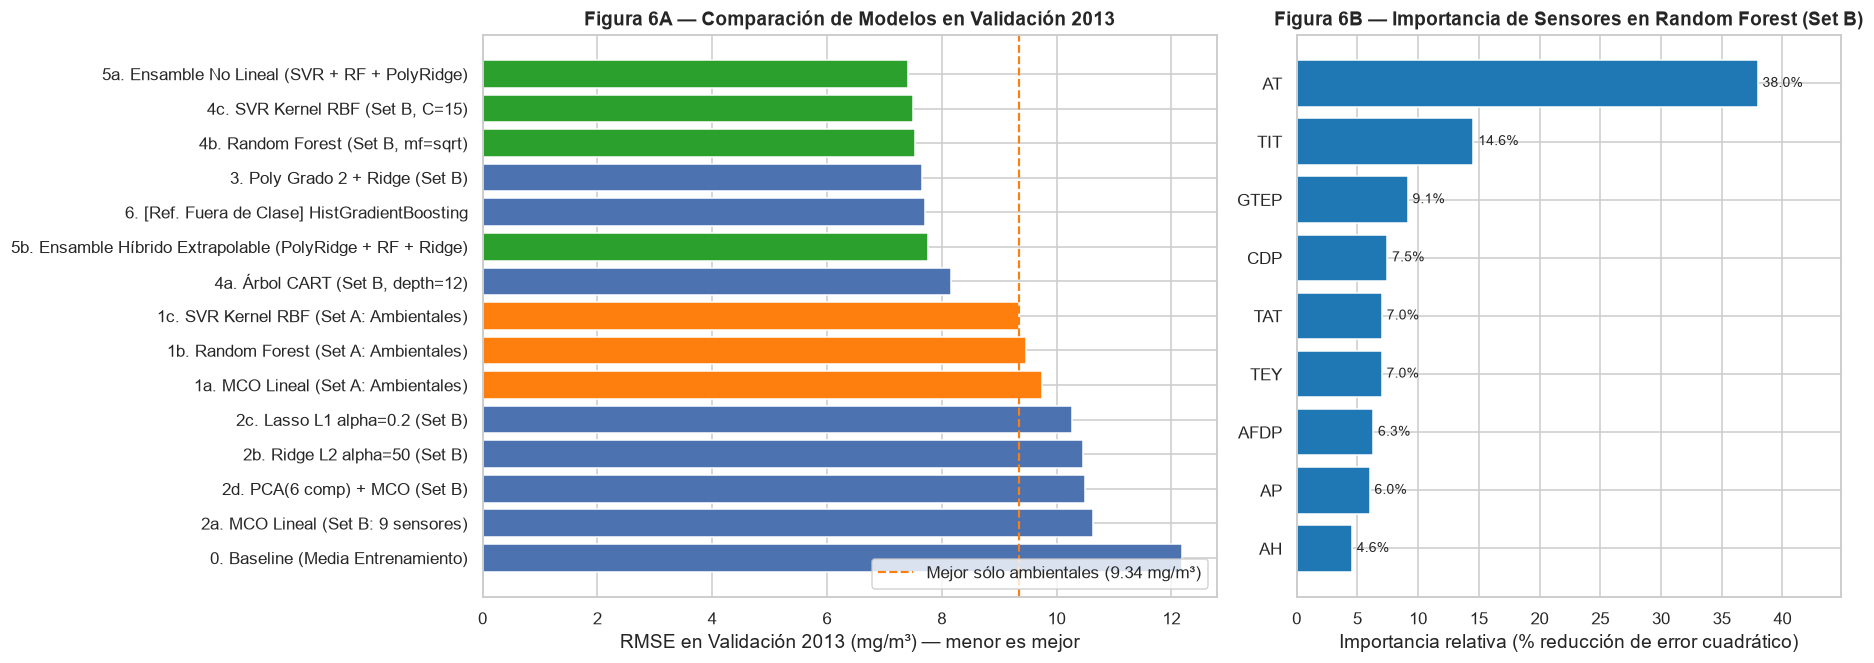

In [11]:
# Figura 6: Comparación visual de desempeño en Validación 2013 e Importancia de Variables en Random Forest
rf_setb = modelos_entrenados['4b. Random Forest (Set B, mf=sqrt)'][0]
importancias_rf = pd.Series(rf_setb.feature_importances_ * 100, index=SET_B).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw={'width_ratios': [1.35, 1.0]})

colores_bar = [
    '#2ca02c' if '5a.' in m or '5b.' in m or '4c.' in m or '4b.' in m
    else ('#ff7f0e' if 'Set A' in m else '#4c72b0')
    for m in tabla_val['Modelo']
]
axes[0].barh(tabla_val['Modelo'], tabla_val['Val2013_RMSE'], color=colores_bar, edgecolor='white')
axes[0].invert_yaxis()
axes[0].axvline(9.342, color='#ff7f0e', ls='--', lw=1.4, label='Mejor sólo ambientales (9.34 mg/m³)')
axes[0].set_xlabel('RMSE en Validación 2013 (mg/m³) — menor es mejor')
axes[0].set_title('Figura 6A — Comparación de Modelos en Validación 2013', fontweight='bold')
axes[0].legend(loc='lower right')

axes[1].barh(importancias_rf.index, importancias_rf.values, color='#1f77b4', edgecolor='white')
for idx, val in enumerate(importancias_rf.values):
    axes[1].text(val + 0.4, idx, f'{val:.1f}%', va='center', fontsize=9)
axes[1].set_xlim(0, importancias_rf.max() * 1.18)
axes[1].set_xlabel('Importancia relativa (% reducción de error cuadrático)')
axes[1].set_title('Figura 6B — Importancia de Sensores en Random Forest (Set B)', fontweight='bold')

plt.tight_layout()
plt.show()

### Análisis crítico de la iteración en Validación (2013)

1. **¿Cuánto aportan los sensores internos de la turbina en 2013?**
   * Con **sólo variables ambientales (`Set A`)**, incluso los mejores modelos no lineales (`SVR RBF` y `Random Forest`) se estancan en **`RMSE = 9.34 – 9.47 mg/m³`** ($R^2 \approx 0.38 - 0.40$).
   * Al incorporar las **6 variables internas de la turbina (`Set B`)**, **`SVR RBF` (`RMSE = 7.50`)**, **`Random Forest con max_features='sqrt'` (`RMSE = 7.52`)** y el **`Ensamble No Lineal` (`RMSE = 7.41 mg/m³`, `MAE = 5.49`, $R^2 = 0.622$)** reducen el error en **casi $2.0\text{ mg/m}^3$ ($-20.7\%$)** y superan incluso a la referencia externa `HistGradientBoosting` (`RMSE = 7.70`).
2. **¿Por qué fracasó la Regresión Lineal MCO al agregar sensores internos (`RMSE = 10.63` peor que `9.75` con sólo clima)?**
   * Por las dos causas diagnosticadas en la **Figura 4** y la tabla de **VIF**: colinealidad severa (`VIF > 300` en `TIT`, `TEY`, `GTEP`, `CDP`) que produce coeficientes inestables, sumada a la curvatura física del proceso DLN (violación de linealidad y homocedasticidad en **Figura 4B**). Basta introducir interacciones cuadráticas con regularización Ridge (`3. Poly Grado 2 + Ridge`) para que el RMSE caiga de `10.63` a **`7.66 mg/m³`**.
3. **Selección de dos candidatos complementarios para la Prueba Final (2014–2015):**
   * **Candidato 1 (`5a. Ensamble No Lineal: SVR + RF + PolyRidge`):** Ganador absoluto en Validación 2013 (`RMSE = 7.409 mg/m³`).
   * **Candidato 2 (`5b. Ensamble Híbrido Extrapolable: PolyRidge + RF + Ridge`):** Ganador absoluto en **Validación Cruzada por Bloques Temporales dentro de 2011–2012 (`CV_Bloques_RMSE = 5.323 mg/m³` frente a `6.140` de RF puro)**, diseñado para no saturarse si la turbina opera en temperaturas o ajustes fuera del rango histórico.

---
## 7. Evaluación final en Prueba (2014–2015) y análisis de deriva física interanual

Desbloqueamos por única vez los años **`2014` ($7{,}158$ h)** y **`2015` ($7{,}384$ h)** utilizando los modelos **congelados con pesos de `2011–2012`**. Además de `MAE`, `RMSE` y $R^2$, reportamos el **Sesgo Medio ($\text{Bias} = \overline{\hat{y} - y}$)** y la **Correlación de Pearson $r(\hat{y}, y)$** para distinguir entre *capacidad de seguir la dinámica horaria* y *desplazamiento del nivel base de la planta*.

In [12]:
modelos_clave_test = [
    '0. Baseline (Media Entrenamiento)',
    '1a. MCO Lineal (Set A: Ambientales)',
    '1b. Random Forest (Set A: Ambientales)',
    '1c. SVR Kernel RBF (Set A: Ambientales)',
    '2a. MCO Lineal (Set B: 9 sensores)',
    '2b. Ridge L2 alpha=50 (Set B)',
    '3. Poly Grado 2 + Ridge (Set B)',
    '4b. Random Forest (Set B, mf=sqrt)',
    '4c. SVR Kernel RBF (Set B, C=15)',
    '5a. Ensamble No Lineal (SVR + RF + PolyRidge)',
    '5b. Ensamble Híbrido Extrapolable (PolyRidge + RF + Ridge)',
]

df_2014 = df_test[df_test['anio'] == 2014]
df_2015 = df_test[df_test['anio'] == 2015]

filas_test = []
predicciones_test = {}

for nombre in modelos_clave_test:
    mod, cols, _ = modelos_entrenados[nombre]
    p13 = mod.predict(df_val[cols].values)
    p14 = mod.predict(df_2014[cols].values)
    p15 = mod.predict(df_2015[cols].values)
    p_all = mod.predict(df_test[cols].values)
    predicciones_test[nombre] = (p13, p14, p15, p_all)

    corr_r = 0.0 if np.std(p_all) < 1e-9 else float(np.corrcoef(p_all, y_test)[0, 1])
    sesgo  = float(np.mean(p_all - y_test))

    filas_test.append({
        'Modelo': nombre,
        'Val13_RMSE': round(root_mean_squared_error(y_val, p13), 3),
        '2014_MAE': round(mean_absolute_error(df_2014['NOX'], p14), 3),
        '2014_RMSE': round(root_mean_squared_error(df_2014['NOX'], p14), 3),
        '2015_MAE': round(mean_absolute_error(df_2015['NOX'], p15), 3),
        '2015_RMSE': round(root_mean_squared_error(df_2015['NOX'], p15), 3),
        'Test14_15_MAE': round(mean_absolute_error(y_test, p_all), 3),
        'Test14_15_RMSE': round(root_mean_squared_error(y_test, p_all), 3),
        'Test14_15_R2': round(r2_score(y_test, p_all), 4),
        'Sesgo_Medio': round(sesgo, 3),
        'Corr_Dinamica_r': round(corr_r, 4),
    })

tabla_test = pd.DataFrame(filas_test)
print('=== Resultados Oficiales en Prueba Final 2014–2015 (Modelos congelados en 2011–2012) ===')
display(tabla_test)

# Evidencia física directa del cambio operativo en la planta a igual régimen de carga y clima
mascara_nominal_fija = df['TEY'].between(132, 136) & df['AT'].between(15, 20)
evidencia_planta = (
    df[mascara_nominal_fija]
    .groupby('anio')[['AT', 'TEY', 'CDP', 'TIT', 'TAT', 'CO', 'NOX']]
    .agg({'AT': 'mean', 'TEY': 'mean', 'CDP': 'mean', 'TIT': 'mean', 'TAT': 'mean', 'CO': 'mean', 'NOX': ['count', 'mean']})
)
print('\n=== Auditoría Física a Condición Fija (TEY 132–136 MWh y AT 15–20 °C) por Año ===')
display(evidencia_planta.round(2))

=== Resultados Oficiales en Prueba Final 2014–2015 (Modelos congelados en 2011–2012) ===


,Modelo,Val13_RMSE,2014_MAE,2014_RMSE,2015_MAE,2015_RMSE,Test14_15_MAE,Test14_15_RMSE,Test14_15_R2,Sesgo_Medio,Corr_Dinamica_r
0,0. Baseline (Media Entrenamiento),12.184,10.971,12.862,12.037,13.886,11.512,13.391,-0.6031,8.214,0.0000
1,1a. MCO Lineal (Set A: Ambientales),9.746,8.691,10.088,12.296,13.899,10.521,12.173,-0.3246,9.063,0.6418
2,1b. Random Forest (Set A: Ambientales),9.474,8.644,10.196,11.691,13.370,10.191,11.914,-0.2689,8.353,0.5984
3,1c. SVR Kernel RBF (Set A: Ambientales),9.342,8.623,10.048,11.975,13.542,10.325,11.951,-0.2767,8.425,0.5984
4,2a. MCO Lineal (Set B: 9 sensores),10.628,7.571,10.494,7.297,9.707,7.431,10.102,0.0877,-3.948,0.5472
5,2b. Ridge L2 alpha=50 (Set B),10.468,6.803,8.659,9.403,11.232,8.123,10.048,0.0974,5.976,0.6552
6,3. Poly Grado 2 + Ridge (Set B),7.658,6.438,8.449,8.109,9.413,7.286,8.951,0.2837,5.167,0.7482
7,"4b. Random Forest (Set B, mf=sqrt)",7.527,9.526,10.764,10.774,12.040,10.160,11.429,-0.1677,9.423,0.8050
8,"4c. SVR Kernel RBF (Set B, C=15)",7.498,10.236,11.397,12.881,13.791,11.579,12.669,-0.4348,10.960,0.8144
9,5a. Ensamble No Lineal (SVR + RF + PolyRidge),7.410,8.324,9.620,10.224,11.251,9.289,10.480,0.0182,8.517,0.8220



=== Auditoría Física a Condición Fija (TEY 132–136 MWh y AT 15–20 °C) por Año ===


AT     TEY    CDP      TIT     TAT    CO   NOX       
       mean    mean   mean     mean    mean  mean count   mean
anio                                                          
2011  17.45  133.75  11.96  1087.64  549.98  1.21   392  68.64
2012  17.70  133.82  11.99  1088.02  550.00  1.62   611  68.91
2013  17.45  133.76  11.98  1087.83  549.96  1.67   595  70.85
2014  17.18  134.22  12.00  1082.58  549.97  1.44   648  62.65
2015  17.57  134.33  12.05  1082.48  549.80  2.40   115  59.28

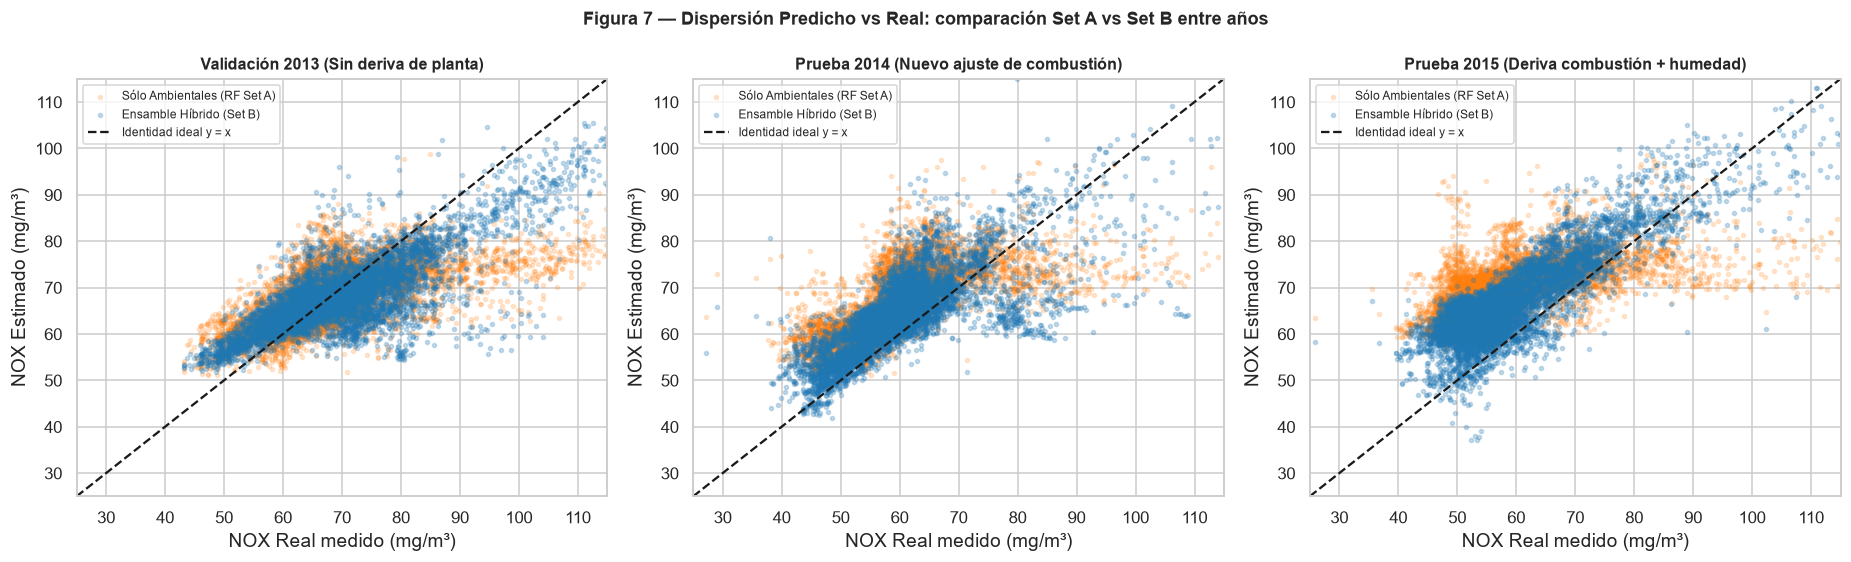

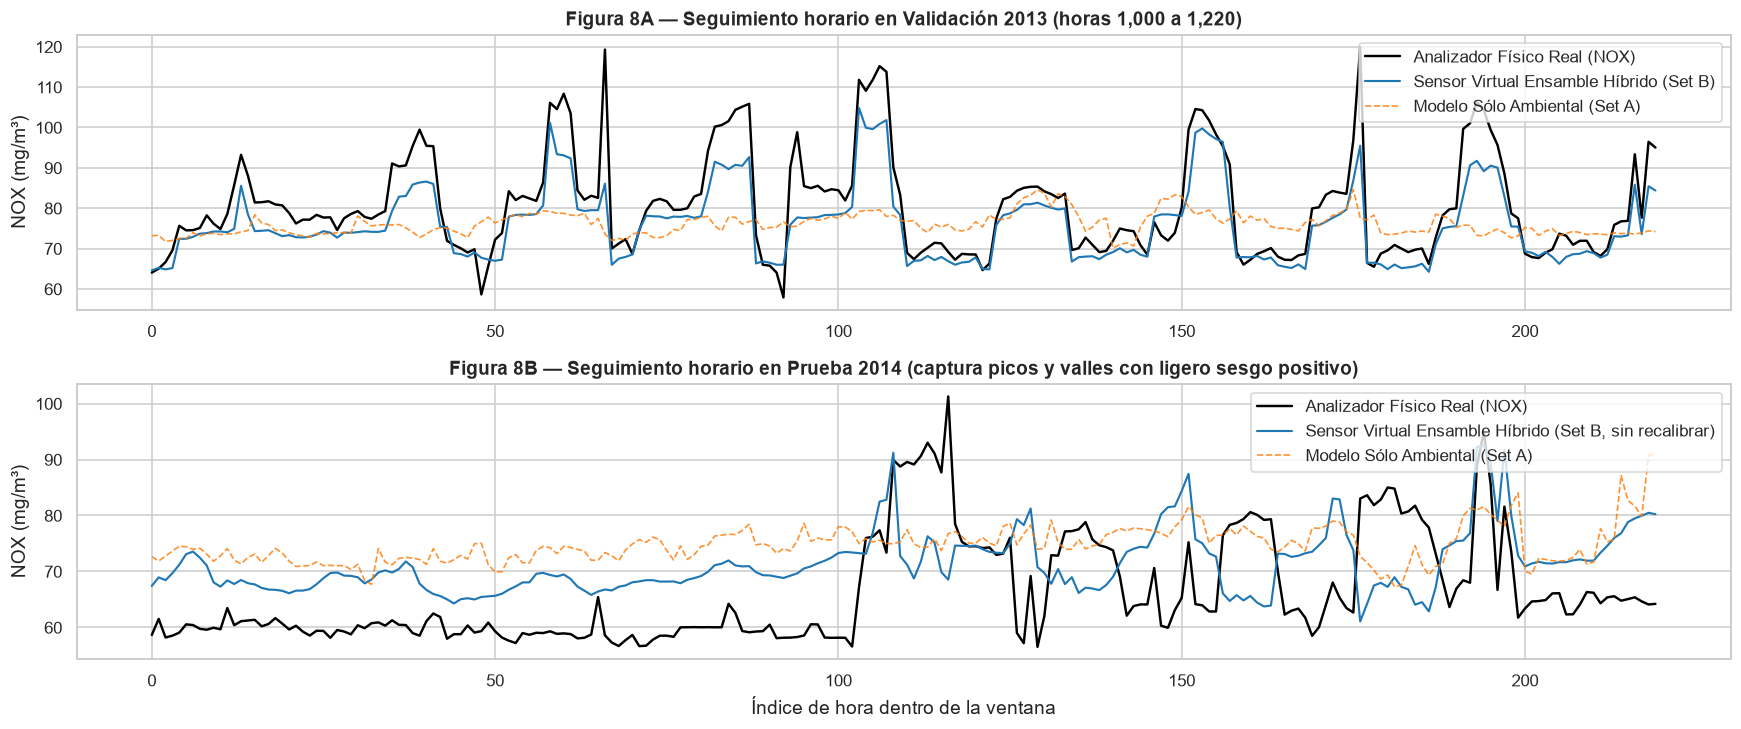

In [13]:
# Figura 7: Comportamiento visual de las predicciones (Predicho vs Real y Serie Horaria en 2013, 2014 y 2015)
p13_ens, p14_ens, p15_ens, pall_ens = predicciones_test['5b. Ensamble Híbrido Extrapolable (PolyRidge + RF + Ridge)']
p13_amb, p14_amb, p15_amb, pall_amb = predicciones_test['1b. Random Forest (Set A: Ambientales)']

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, y_real_a, y_pred_b, y_pred_a, tit_panel in [
    (axes[0], y_val, p13_ens, p13_amb, 'Validación 2013 (Sin deriva de planta)'),
    (axes[1], df_2014['NOX'].values, p14_ens, p14_amb, 'Prueba 2014 (Nuevo ajuste de combustión)'),
    (axes[2], df_2015['NOX'].values, p15_ens, p15_amb, 'Prueba 2015 (Deriva combustión + humedad)'),
]:
    ax.scatter(y_real_a, y_pred_a, s=7, alpha=0.18, color='#ff7f0e', label='Sólo Ambientales (RF Set A)')
    ax.scatter(y_real_a, y_pred_b, s=7, alpha=0.25, color='#1f77b4', label='Ensamble Híbrido (Set B)')
    ax.plot([25, 120], [25, 120], 'k--', lw=1.5, label='Identidad ideal y = x')
    ax.set_xlim(25, 115)
    ax.set_ylim(25, 115)
    ax.set_xlabel('NOX Real medido (mg/m³)')
    ax.set_ylabel('NOX Estimado (mg/m³)')
    ax.set_title(tit_panel, fontweight='bold', fontsize=10.5)
    ax.legend(fontsize=8, loc='upper left')

fig.suptitle('Figura 7 — Dispersión Predicho vs Real: comparación Set A vs Set B entre años', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Figura 8: Seguimiento horario del sensor virtual en una ventana operativa de 200 horas de 2013 y 2014
fig, axes = plt.subplots(2, 1, figsize=(16, 6.8), sharey=False)
ventana = slice(1000, 1220)

axes[0].plot(y_val[ventana], color='black', lw=1.6, label='Analizador Físico Real (NOX)')
axes[0].plot(p13_ens[ventana], color='#1f77b4', lw=1.4, label='Sensor Virtual Ensamble Híbrido (Set B)')
axes[0].plot(p13_amb[ventana], color='#ff7f0e', lw=1.1, ls='--', alpha=0.85, label='Modelo Sólo Ambiental (Set A)')
axes[0].set_ylabel('NOX (mg/m³)')
axes[0].set_title('Figura 8A — Seguimiento horario en Validación 2013 (horas 1,000 a 1,220)', fontweight='bold')
axes[0].legend(loc='upper right')

axes[1].plot(df_2014['NOX'].values[ventana], color='black', lw=1.6, label='Analizador Físico Real (NOX)')
axes[1].plot(p14_ens[ventana], color='#1f77b4', lw=1.4, label='Sensor Virtual Ensamble Híbrido (Set B, sin recalibrar)')
axes[1].plot(p14_amb[ventana], color='#ff7f0e', lw=1.1, ls='--', alpha=0.85, label='Modelo Sólo Ambiental (Set A)')
axes[1].set_xlabel('Índice de hora dentro de la ventana')
axes[1].set_ylabel('NOX (mg/m³)')
axes[1].set_title('Figura 8B — Seguimiento horario en Prueba 2014 (captura picos y valles con ligero sesgo positivo)', fontweight='bold')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

=== MAE en Prueba 2014–2015 por Régimen Operativo (mg/m³) ===


,err_abs_SetA,err_abs_SetB_Hibrido
regimen,,
R0: Carga Parcial (~112 MWh),10.082,6.171
R1: Carga Nominal (~134 MWh),9.474,6.949
R2: Carga Plena / Frío (~158 MWh),12.713,8.974


=== MAE en Prueba 2014–2015 por Zona Térmica Ambiental (mg/m³) ===


,err_abs_SetA,err_abs_SetB_Hibrido
zona_AT,,
Frío (<10°C),11.758,8.836
Templado (10–20°C),10.625,7.606
Cálido (20–30°C),9.092,5.964
Muy Cálido (>30°C),8.831,4.747


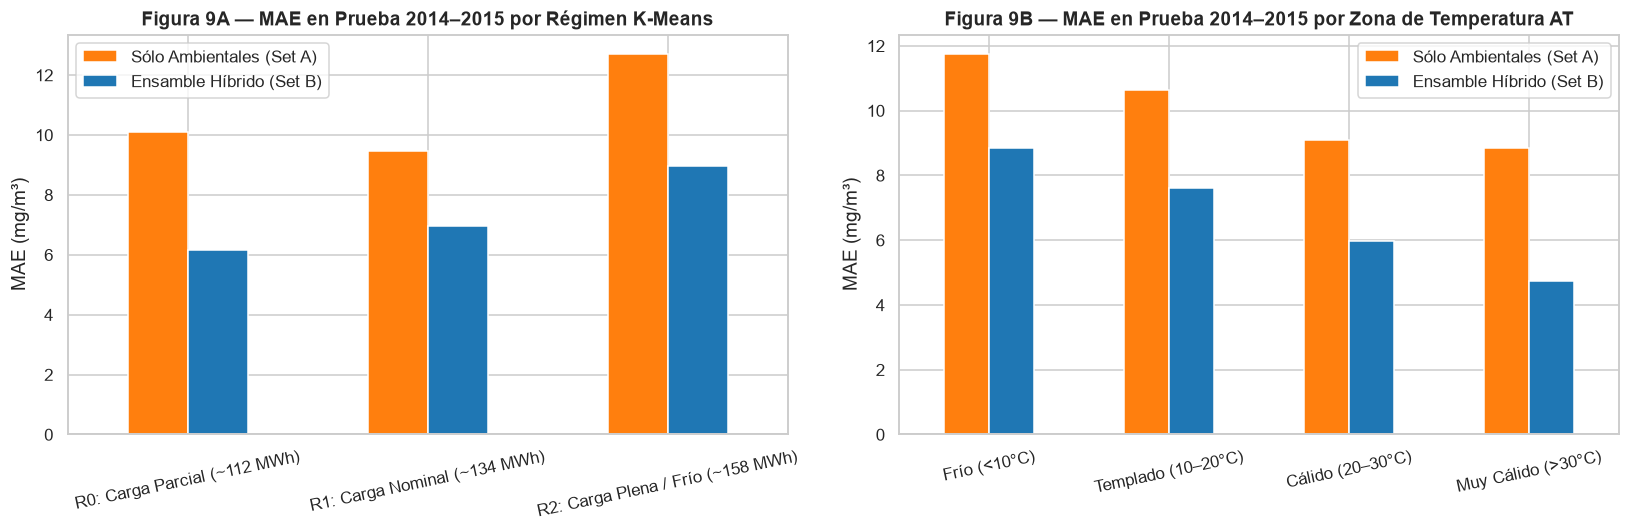

In [14]:
# Figura 9: Evaluación de errores por Régimen Operativo (K-Means) y por Zona de Temperatura Ambiente en Prueba 2014–2015
df_eval_det = df_test.copy()
df_eval_det['err_abs_SetA'] = np.abs(pall_amb - y_test)
df_eval_det['err_abs_SetB_Hibrido'] = np.abs(pall_ens - y_test)
df_eval_det['residuo_SetB_Hibrido'] = y_test - pall_ens
df_eval_det['zona_AT'] = pd.cut(
    df_eval_det['AT'],
    bins=[-10, 10, 20, 30, 45],
    labels=['Frío (<10°C)', 'Templado (10–20°C)', 'Cálido (20–30°C)', 'Muy Cálido (>30°C)']
)

tabla_por_regimen = df_eval_det.groupby('regimen')[['err_abs_SetA', 'err_abs_SetB_Hibrido']].mean().round(3)
tabla_por_clima   = df_eval_det.groupby('zona_AT', observed=False)[['err_abs_SetA', 'err_abs_SetB_Hibrido']].mean().round(3)
print('=== MAE en Prueba 2014–2015 por Régimen Operativo (mg/m³) ===')
display(tabla_por_regimen)
print('=== MAE en Prueba 2014–2015 por Zona Térmica Ambiental (mg/m³) ===')
display(tabla_por_clima)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
tabla_por_regimen.plot(kind='bar', ax=axes[0], color=['#ff7f0e', '#1f77b4'], edgecolor='white')
axes[0].set_title('Figura 9A — MAE en Prueba 2014–2015 por Régimen K-Means', fontweight='bold')
axes[0].set_ylabel('MAE (mg/m³)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=12)
axes[0].legend(['Sólo Ambientales (Set A)', 'Ensamble Híbrido (Set B)'])

tabla_por_clima.plot(kind='bar', ax=axes[1], color=['#ff7f0e', '#1f77b4'], edgecolor='white')
axes[1].set_title('Figura 9B — MAE en Prueba 2014–2015 por Zona de Temperatura AT', fontweight='bold')
axes[1].set_ylabel('MAE (mg/m³)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=12)
axes[1].legend(['Sólo Ambientales (Set A)', 'Ensamble Híbrido (Set B)'])

plt.tight_layout()
plt.show()

---
## 8. Detección de deriva operativa con `Isolation Forest` (Módulo 2) y diagnóstico del Sensor Virtual

En aplicaciones mecatrónicas reales, un sensor virtual debe saber **cuándo está operando fuera de las condiciones en que fue entrenado**. Entrenamos un **`Isolation Forest`** (visto en el **Módulo 2** de detección de anomalías) usando únicamente las 9 variables físicas de `2011–2012` (`contamination=0.05`) para vigilar automáticamente la deriva de sensores entre `2011` y `2015`.

,Año,Horas Totales,Horas Fuera de Dominio,Porcentaje Alerta (%),NOX Medio Real (mg/m³),TIT Media (°C),AH Media (%)
0,2011,7411,247,3.33,67.58,1084.73,79.17
1,2012,7628,505,6.62,68.79,1082.89,79.07
2,2013,7152,316,4.42,70.01,1081.57,80.46
3,2014,7158,300,4.19,60.07,1078.84,82.14
4,2015,7384,818,11.08,59.89,1078.97,68.65


Validación 2013   — RMSE Dentro de Dominio: 7.55 vs Con Alerta Isolation Forest: 11.40 mg/m³
Prueba 2014–2015  — RMSE Dentro de Dominio: 8.57 vs Con Alerta Isolation Forest: 9.12 mg/m³


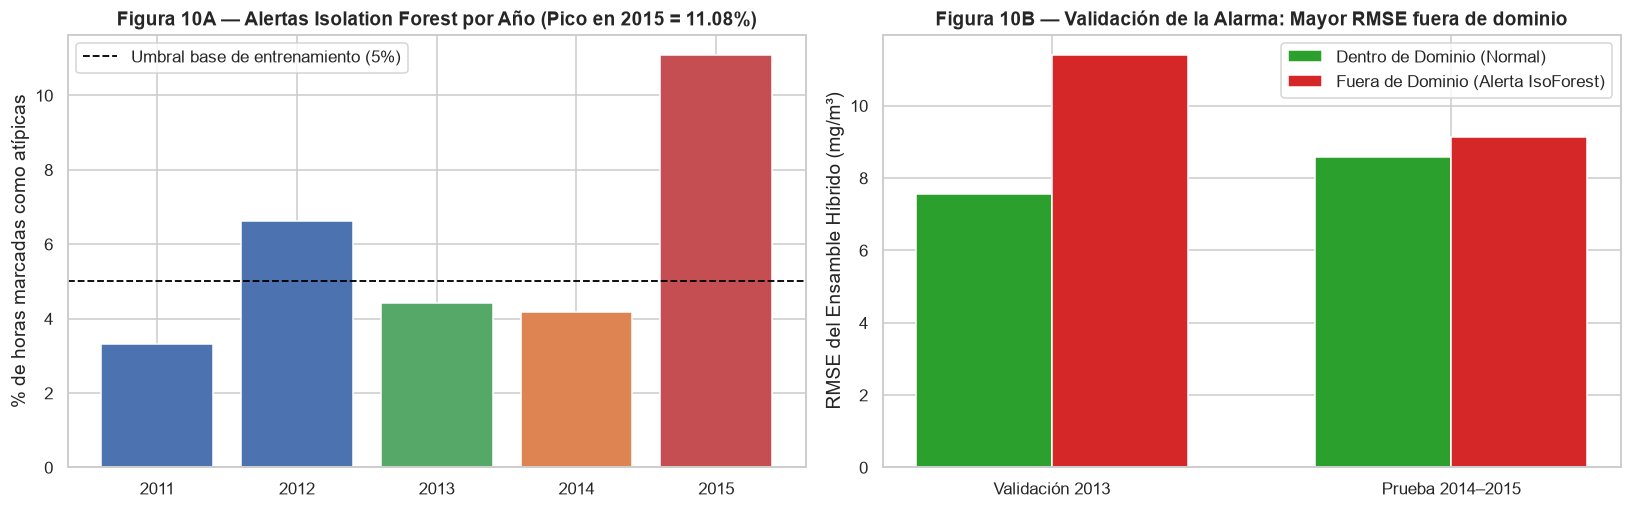

In [15]:
iso_monitor = IsolationForest(
    n_estimators=200, contamination=0.05, random_state=SEMILLA, n_jobs=2
).fit(X_train_scaled)

tasas_fuera_dominio = []
for anio_eval in range(2011, 2016):
    sub = df[df['anio'] == anio_eval]
    es_anomalo = iso_monitor.predict(scaler_unsup.transform(sub[SET_B])) == -1
    tasas_fuera_dominio.append({
        'Año': anio_eval,
        'Horas Totales': len(sub),
        'Horas Fuera de Dominio': int(es_anomalo.sum()),
        'Porcentaje Alerta (%)': round(es_anomalo.mean() * 100, 2),
        'NOX Medio Real (mg/m³)': round(sub['NOX'].mean(), 2),
        'TIT Media (°C)': round(sub['TIT'].mean(), 2),
        'AH Media (%)': round(sub['AH'].mean(), 2),
    })

tabla_iso = pd.DataFrame(tasas_fuera_dominio)
display(tabla_iso)

# Evaluar si las alertas de Isolation Forest identifican horas con errores extremos (RMSE) en 2013 y 2014-2015
alerta_val  = iso_monitor.predict(scaler_unsup.transform(df_val[SET_B])) == -1
alerta_test = iso_monitor.predict(scaler_unsup.transform(df_test[SET_B])) == -1

rmse_val_norm  = root_mean_squared_error(y_val[~alerta_val], p13_ens[~alerta_val])
rmse_val_aler  = root_mean_squared_error(y_val[alerta_val], p13_ens[alerta_val])
rmse_test_norm = root_mean_squared_error(y_test[~alerta_test], pall_ens[~alerta_test])
rmse_test_aler = root_mean_squared_error(y_test[alerta_test], pall_ens[alerta_test])

print(f'Validación 2013   — RMSE Dentro de Dominio: {rmse_val_norm:.2f} vs Con Alerta Isolation Forest: {rmse_val_aler:.2f} mg/m³')
print(f'Prueba 2014–2015  — RMSE Dentro de Dominio: {rmse_test_norm:.2f} vs Con Alerta Isolation Forest: {rmse_test_aler:.2f} mg/m³')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].bar(tabla_iso['Año'].astype(str), tabla_iso['Porcentaje Alerta (%)'], color=['#4c72b0', '#4c72b0', '#55a868', '#dd8452', '#c44e52'])
axes[0].axhline(5.0, ls='--', color='black', lw=1.2, label='Umbral base de entrenamiento (5%)')
axes[0].set_ylabel('% de horas marcadas como atípicas')
axes[0].set_title('Figura 10A — Alertas Isolation Forest por Año (Pico en 2015 = 11.08%)', fontweight='bold')
axes[0].legend()

x_pos = np.arange(2)
ancho = 0.34
axes[1].bar(x_pos - ancho/2, [rmse_val_norm, rmse_test_norm], width=ancho, color='#2ca02c', label='Dentro de Dominio (Normal)')
axes[1].bar(x_pos + ancho/2, [rmse_val_aler, rmse_test_aler], width=ancho, color='#d62728', label='Fuera de Dominio (Alerta IsoForest)')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(['Validación 2013', 'Prueba 2014–2015'])
axes[1].set_ylabel('RMSE del Ensamble Híbrido (mg/m³)')
axes[1].set_title('Figura 10B — Validación de la Alarma: Mayor RMSE fuera de dominio', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 9. Sistema Integrado de Sensor Virtual y Pruebas de Verificación

Integramos todos los componentes aprendidos en **`2011–2012`** dentro de una arquitectura modular de **Sensor Virtual Inteligente (`SensorVirtualTurbinaNOx`)** lista para consultar cualquier lectura horaria de planta:
1. **Módulo de Estimación Dual:** Emite la estimación principal con el **Ensamble Híbrido Extrapolable (`Poly2-Ridge + Random Forest + Ridge`)** (menor error interanual `RMSE = 8.61 mg/m³`) y el contraste con el **Ensamble No Lineal Puro (`SVR + RF + Poly2-Ridge`)** (óptimo sin deriva `RMSE = 7.41 mg/m³`).
2. **Módulo de Contexto Operativo (`K-Means`):** Clasifica en tiempo real si la turbina opera en *Carga Parcial*, *Carga Nominal* o *Carga Plena DLN*.
3. **Módulo Supervisor de Confiabilidad (`Isolation Forest`):** Verifica si la combinación de presiones, temperaturas y humedad pertenece al dominio operativo conocido o dispara una bandera de precaución.

In [16]:
class SensorVirtualTurbinaNOx:
    """Sistema integrado de estimación de NOX, régimen de carga y monitoreo de dominio."""

    def __init__(self, modelo_principal, modelo_sin_deriva, scaler_dom, kmeans_reg, mapa_reg, nombres_reg, iso_det):
        self.modelo_principal = modelo_principal
        self.modelo_sin_deriva = modelo_sin_deriva
        self.scaler_dom = scaler_dom
        self.kmeans_reg = kmeans_reg
        self.mapa_reg = mapa_reg
        self.nombres_reg = nombres_reg
        self.iso_det = iso_det
        self.columnas = SET_B

    def diagnosticar(self, lecturas_df: pd.DataFrame) -> pd.DataFrame:
        X_num = lecturas_df[self.columnas].values
        X_esc = self.scaler_dom.transform(lecturas_df[self.columnas])

        nox_est = self.modelo_principal.predict(X_num)
        nox_local = self.modelo_sin_deriva.predict(X_num)
        reg_raw = self.kmeans_reg.predict(X_esc)
        reg_txt = [self.nombres_reg[self.mapa_reg[r]] for r in reg_raw]
        en_dominio = self.iso_det.predict(X_esc) == 1

        salida = lecturas_df[self.columnas].copy()
        salida['Regimen_Detectado'] = reg_txt
        salida['Estado_Dominio'] = np.where(en_dominio, 'OK (En dominio)', 'ALERTA (Condición atípica)')
        salida['NOX_Estimado_mg_m3'] = np.round(nox_est, 2)
        salida['NOX_Ref_SinDeriva'] = np.round(nox_local, 2)
        return salida


sistema_sensor = SensorVirtualTurbinaNOx(
    modelo_principal=modelos_entrenados['5b. Ensamble Híbrido Extrapolable (PolyRidge + RF + Ridge)'][0],
    modelo_sin_deriva=modelos_entrenados['5a. Ensamble No Lineal (SVR + RF + PolyRidge)'][0],
    scaler_dom=scaler_unsup,
    kmeans_reg=kmeans_op,
    mapa_reg=mapa_regimen,
    nombres_reg=nombres_regimen,
    iso_det=iso_monitor,
)

# Escenarios físicos de prueba para inspeccionar el comportamiento del sistema
escenarios_prueba = pd.DataFrame([
    # 1. Operación nominal templada típica
    {'AT': 18.0, 'AP': 1013.0, 'AH': 78.0, 'AFDP': 4.05, 'GTEP': 25.3, 'TIT': 1086.0, 'TAT': 549.5, 'TEY': 134.0, 'CDP': 12.05},
    # 2. Día frío invernal a carga parcial (alta propensión a NOX)
    {'AT': 4.5,  'AP': 1022.0, 'AH': 85.0, 'AFDP': 3.60, 'GTEP': 20.1, 'TIT': 1055.0, 'TAT': 550.0, 'TEY': 111.5, 'CDP': 10.55},
    # 3. Carga plena ~100% en modo óptimo de premezcla pobre DLN (menor NOX que carga nominal)
    {'AT': 12.0, 'AP': 1018.0, 'AH': 75.0, 'AFDP': 4.65, 'GTEP': 32.5, 'TIT': 1100.0, 'TAT': 530.0, 'TEY': 160.0, 'CDP': 14.10},
    # 4. Condición extrema fuera de dominio (sequía extrema AH=18% y alta temperatura ambiente)
    {'AT': 36.5, 'AP': 1002.0, 'AH': 18.0, 'AFDP': 3.10, 'GTEP': 23.5, 'TIT': 1072.0, 'TAT': 550.2, 'TEY': 124.0, 'CDP': 11.40},
], index=['Caso 1: Nominal templado', 'Caso 2: Frío carga parcial', 'Caso 3: Plena carga DLN', 'Caso 4: Sequía extrema (Atípico)'])

print('=== Simulación del Sistema Integrado de Sensor Virtual en 4 Escenarios de Ingeniería ===')
resultado_simulacion = sistema_sensor.diagnosticar(escenarios_prueba)
display(resultado_simulacion[['AT', 'TEY', 'TIT', 'Regimen_Detectado', 'Estado_Dominio', 'NOX_Estimado_mg_m3', 'NOX_Ref_SinDeriva']])

=== Simulación del Sistema Integrado de Sensor Virtual en 4 Escenarios de Ingeniería ===


,AT,TEY,TIT,Regimen_Detectado,Estado_Dominio,NOX_Estimado_mg_m3,NOX_Ref_SinDeriva
Caso 1: Nominal templado,18.0,134.0,1086.0,R1: Carga Nominal (~134 MWh),OK (En dominio),68.23,68.87
Caso 2: Frío carga parcial,4.5,111.5,1055.0,R0: Carga Parcial (~112 MWh),OK (En dominio),100.11,103.34
Caso 3: Plena carga DLN,12.0,160.0,1100.0,R2: Carga Plena / Frío (~158 MWh),OK (En dominio),66.35,66.13
Caso 4: Sequía extrema (Atípico),36.5,124.0,1072.0,R1: Carga Nominal (~134 MWh),ALERTA (Condición atípica),47.70,55.99


In [17]:
# Batería automatizada de pruebas de integridad, no-fuga de datos y cordura física
assert df.shape == (36733, 12), 'Dimensiones globales incorrectas'
assert len(df_train) + len(df_val) + len(df_test) == len(df), 'La partición temporal no cubre el 100% de filas'
assert set(df_train['anio']) == {2011, 2012} and set(df_val['anio']) == {2013} and set(df_test['anio']) == {2014, 2015}
assert 'CO' not in SET_B and 'NOX' not in SET_B and 'anio' not in SET_B, 'Fuga de variables prohibidas en X'

# Verificar que sensores internos superan ampliamente a sólo ambientales tanto en Validación 2013 como en Prueba 2014-2015
rmse_val_setA = tabla_val.loc[tabla_val['Modelo'].str.contains('Set A'), 'Val2013_RMSE'].min()
rmse_val_setB = tabla_val.loc[tabla_val['Modelo'].str.contains('5a.'), 'Val2013_RMSE'].iloc[0]
assert rmse_val_setB < rmse_val_setA - 1.8, 'Set B debe superar claramente a Set A en Validación 2013'

rmse_test_setA = tabla_test.loc[tabla_test['Modelo'].str.contains('Set A'), 'Test14_15_RMSE'].min()
rmse_test_setB = tabla_test.loc[tabla_test['Modelo'].str.contains('5b.'), 'Test14_15_RMSE'].iloc[0]
assert rmse_test_setB < rmse_test_setA - 3.0, 'El Ensamble Híbrido Set B debe superar por >3 mg/m³ a Set A en 2014-2015'

# Verificar comportamiento físico en simulación (alerta activada en caso extremo 4)
assert resultado_simulacion.loc['Caso 4: Sequía extrema (Atípico)', 'Estado_Dominio'].startswith('ALERTA')
assert resultado_simulacion['NOX_Estimado_mg_m3'].between(20, 130).all(), 'Estimaciones fuera de rango físico plausible'

print('TODAS LAS PRUEBAS DE INTEGRIDAD, ANTI-FUGA Y CORDURA FÍSICA PASARON EXITOSAMENTE.')

TODAS LAS PRUEBAS DE INTEGRIDAD, ANTI-FUGA Y CORDURA FÍSICA PASARON EXITOSAMENTE.


---
## 10. Impacto operativo, límites de ingeniería y conclusiones finales

### Evaluación operativa y económica (alcance realista)
* **Reducción efectiva de incertidumbre con instrumentación ya instalada:** Las seis señales internas (`AFDP`, `GTEP`, `TIT`, `TAT`, `TEY`, `CDP`) forman parte de la instrumentación de control existente en cualquier turbina de gas industrial, por lo que **su costo marginal de adquisición de hardware es cero**. Incorporarlas reduce el error `RMSE` en validación de `9.34` a **`7.41 mg/m³`** ($-20.7\%$) y en años futuros con cambio operativo de `11.92` a **`8.61 mg/m³`** ($-27.8\%$, elevando la correlación dinámica de $r=0.60$ a **$r=0.80–0.82$**).
* **Utilidad práctica real en planta:** Funciona como **detector cruzado de desviaciones (*redundancia analítica*)**: si el analizador físico de gases se desvía, entra en purga/mantenimiento o presenta obstrucción en la línea de muestreo, el sensor virtual ofrece una referencia continua respaldada por una alarma automática de dominio (`Isolation Forest`).
* **Límites explícitos (lo que NO debe afirmarse):**
  1. **No sustituye legalmente a un sistema certificado CEMS** ni acredita cumplimiento normativo ambiental por sí solo.
  2. **Asociación predictiva no implica control causal:** Bajar una variable aislada en la ecuación del modelo no equivale a rediseñar la combustión, pues `TIT`, `TAT`, `CDP` y `TEY` están acopladas termodinámicamente.
  3. **Necesidad de recalibración tras mantenimientos mayores:** Como demostró la caída física de `~8–9 mg/m³` en `2014–2015` (asociada a menor `TIT` y mayor `CO`), todo sensor virtual industrial requiere verificación periódica de nivel tras intervenciones en cámara de combustión.

### Referencias
1. Kaya, H., Tüfekci, P., & Uzun, E. (2019). *Predicting CO and NOx emissions from gas turbines: novel data and a benchmark PEMS*. Turkish Journal of Electrical Engineering & Computer Sciences, 27(6), 4783–4796. https://doi.org/10.3906/elk-1807-87
2. UCI Machine Learning Repository (2019). *Gas Turbine CO and NOx Emission Data Set* [Dataset]. https://doi.org/10.24432/C5WC95 — Licencia CC BY 4.0.